# Controle do carro por gestos, sem tirar os olhos da estrada

Trabalho final da disciplina de Deep Learning (Insper), tema mobilidade e segurança. Este notebook reúne o projeto inteiro: os passos, os comandos, todo o código, os resultados e o diário.

**Tese:** um comando por gesto só é viável se quase nunca disparar sozinho. A métrica principal é a taxa de ativação acidental, e não a acurácia.

**Situação em 04/11/2026:**
- **Pronto:** CNN 3D treinada do zero no Jester, com 92,6% de acerto no teste, além da demo na webcam e do player por gestos.
- **Ainda sem resultado:** o experimento central no volante (DriverMHG), a comparação com e sem pré-treino, os falsos disparos no volante, RGB × infravermelho, latência e tamanho do vocabulário.

**Índice**
1. Como usar este notebook
2. Passo a passo do que foi feito
3. Como reproduzir (comandos)
4. Todo o código
5. Resultados, lidos dos arquivos
6. Coleta de dados no carro
7. Próximos passos
8. Diário

**Licenças:** este notebook não traz frames de nenhum dataset. O DriverMHG limita a publicação a 10 frames e 2 clipes sem aprovação da TUM, e a licença do Jester trata os dados como confidenciais. Cada integrante do grupo deve baixar a própria cópia.

## 1. Como usar este notebook

- **Seção 4 (código):** cada célula usa `%%writefile` para recriar um arquivo do projeto. Essas células ficam marcadas com `skip-execution`, mas o botão **Run All** do VS Code ou do Jupyter pode ignorar a marca e sobrescrever os arquivos com este mesmo conteúdo.
- **Seção 5 (resultados):** as células leem os arquivos de `resultados/`, para que nenhum número seja copiado à mão. As células só leem arquivos: não treinam nem baixam nada.
- **Ambiente:** selecione o kernel do `.venv` deste projeto.

## 2. Passo a passo do que foi feito

| # | Passo | Resultado |
|---|---|---|
| 1 | Verificar acesso e licença dos datasets | DriverMHG: 19,95 GB, sem cadastro. Jester: 22,93 GB, público, licença só para pesquisa |
| 2 | Criar a estrutura do projeto | Pastas, `README.md` e `.gitignore` |
| 3 | Baixar o DriverMHG sem a profundidade | O RAR não é sólido, então dá para pular a profundidade: cerca de 10 GB em vez de 20 GB. Em andamento: 69 de 125 gravações |
| 4 | Explorar o DriverMHG | 5.148 segmentos, 25 pessoas, cerca de 0,94 s por segmento (`notebooks/01_exploracao.ipynb`) |
| 5 | Baixar o Jester em um arquivo único | 5.279.581 frames em um binário com índice, em vez de milhões de arquivos |
| 6 | Criar as redes do zero | CNN 3D e CNN 2D + GRU e, depois, CNN 2D + transformer |
| 7 | Treino pequeno (20 mil vídeos, 8 épocas) | CNN 3D com 82,8% de acerto na validação de 5 mil vídeos |
| 8 | Testar punição forte de falsa ativação | Peso 5 piorou o modelo: menos gestos no mesmo nível de falsa ativação |
| 9 | Comparar arquiteturas | Transformer com 15,2%, com a mesma taxa de aprendizado. A GRU foi interrompida na 2ª época, então não há conclusão sobre ela |
| 10 | Primeira demo na webcam | Validação de 80%, mas o gesto rápido falhava: a validação não previu esse problema |
| 11 | Corrigir janela e treino | Janelas de 1, 1,5 e 3 s na demo; gestos mais rápidos, mão menor e fora do centro no treino |
| 12 | Treino médio (40 mil vídeos, 10 épocas) | 85,0% na validação; na webcam, reconhecimento bem melhor |
| 13 | Medir falsos disparos em fluxo simulado | 0,02 por min com 29,4% dos gestos detectados no modelo médio |
| 14 | Criar o player por gestos | Esquerda volta, direita avança, sinal de pare alterna play e pause |
| 15 | Treino grande (118.562 vídeos, 20 épocas) | **92,6% no teste**; 0,03 falso por min com 71,8% dos gestos detectados |

**Tela azul:** durante o treino médio, o Windows reiniciou com o erro `0x113`, ligado à NVIDIA. O treino retomou da última época salva. A causa exata não foi determinada.

**Pausa:** o treino grande foi pausado às 18h21 com 8 épocas salvas e retomado às 19h53, sem perda.

## 3. Como reproduzir (comandos)

Os comandos rodam na raiz do projeto, no Windows, com o Git Bash.

### Ambiente

```bash
uv venv .venv --python 3.12
uv pip install --python .venv/Scripts/python.exe torch --index-url https://download.pytorch.org/whl/cu130
uv pip install --python .venv/Scripts/python.exe -r requirements.txt
```

### Dados

```bash
# Jester: cerca de 35 min a 11 MB/s
.venv/Scripts/python.exe -u src/baixar_jester.py --destino data/Jester
# Os rótulos ficam em data/Jester/rotulos/jester_labels, vindos de:
# https://apigwx-aws.qualcomm.com/qsc/public/v1/api/download/software/dataset/AIDataset/Jester/jester-labels

# DriverMHG sem profundidade: retoma sozinho e a velocidade varia bastante
python -u src/baixar_drivermhg.py --destino data/DriverMHG
.venv/Scripts/python.exe -u src/preparar_drivermhg.py --base data/DriverMHG
```

### Treino no Jester

```bash
# Treino pequeno de validação da ideia (cerca de 15 min)
.venv/Scripts/python.exe -u src/treinar_jester.py --modelo cnn_3d --nome cnn_3d_pequeno --epocas 8 --limite-treino 20000

# Treino médio (cerca de 45 min)
.venv/Scripts/python.exe -u src/treinar_jester.py --modelo cnn_3d --nome cnn_3d_medio --epocas 10 --limite-treino 40000 \
  --peso-falso 1 --frac-sinteticos 0.1 --aug-tempo --aug-espaco --suavizacao 0.05

# Treino grande (cerca de 4,5 h); acrescente --retomar para continuar da última época salva
.venv/Scripts/python.exe -u src/treinar_jester.py --modelo cnn_3d --nome cnn_3d --epocas 20 \
  --peso-falso 1 --frac-sinteticos 0.1 --aug-tempo --aug-espaco --suavizacao 0.05
```

### Avaliação

```bash
.venv/Scripts/python.exe -u src/avaliar_jester.py --modelo resultados/jester/cnn_3d/melhor.pt --limite 14787
.venv/Scripts/python.exe -u src/calibrar_fluxo.py --modelo resultados/jester/cnn_3d/melhor.pt
```

### Ajuste no DriverMHG (ainda não rodou de verdade)

```bash
.venv/Scripts/python.exe -u src/treinar_drivermhg.py --modelo cnn_3d --mao direita --modalidade ir --inicio zero
.venv/Scripts/python.exe -u src/treinar_drivermhg.py --modelo cnn_3d --mao direita --modalidade ir --inicio resultados/jester/cnn_3d/melhor.pt
```

### Demos

Dois cliques em `demo/abrir_camera.bat` (tela de teste) ou `demo/abrir_player.bat` (player). As duas usam a mesma câmera, então só uma pode ficar aberta por vez.

## 4. Todo o código

Sem pesos pré-treinados de terceiros: as redes começam com inicialização aleatória.

### `src/modelos.py`

As redes: CNN 2D + GRU, CNN 2D + transformer e CNN 3D, e a adaptação do número de canais de entrada.

In [ ]:
%%writefile src/modelos.py
"""Redes de vídeo treinadas do zero, com inicialização aleatória e sem pesos de terceiros.

Entrada: tensor (lote, tempo, canais, altura, largura).
"""
import torch
from torch import nn


def _bloco_2d(entrada, saida):
    return nn.Sequential(nn.Conv2d(entrada, saida, 3, padding=1, bias=False), nn.BatchNorm2d(saida), nn.ReLU(inplace=True),
                         nn.Conv2d(saida, saida, 3, padding=1, bias=False), nn.BatchNorm2d(saida), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))


class CNNGRU(nn.Module):
    """CNN 2D aplicada a cada frame, seguida de uma GRU sobre a sequência."""

    def __init__(self, n_classes, canais_entrada=3, canais=(32, 64, 128, 256), oculta=256, dropout=0.3):
        super().__init__()
        camadas, entrada = [], canais_entrada
        for saida in canais:
            camadas.append(_bloco_2d(entrada, saida))
            entrada = saida
        self.corpo = nn.Sequential(*camadas, nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.gru = nn.GRU(entrada, oculta, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.cabeca = nn.Linear(oculta, n_classes)

    def forward(self, x):
        lote, tempo = x.shape[:2]
        h = self.corpo(x.flatten(0, 1)).view(lote, tempo, -1)
        saida, _ = self.gru(h)
        return self.cabeca(self.dropout(saida.mean(dim=1)))


class CNNTransformer(nn.Module):
    """A mesma CNN 2D por frame da CNNGRU, com atenção temporal no lugar da GRU."""

    def __init__(self, n_classes, canais_entrada=3, canais=(32, 64, 128, 256), camadas_atencao=2,
                 cabecas=4, n_frames=16, dropout=0.3):
        super().__init__()
        blocos, entrada = [], canais_entrada
        for saida in canais:
            blocos.append(_bloco_2d(entrada, saida))
            entrada = saida
        self.corpo = nn.Sequential(*blocos, nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.posicao = nn.Parameter(torch.zeros(1, n_frames, entrada))
        nn.init.trunc_normal_(self.posicao, std=0.02)
        camada = nn.TransformerEncoderLayer(entrada, cabecas, dim_feedforward=2 * entrada, dropout=0.1,
                                            batch_first=True, norm_first=True)
        self.atencao = nn.TransformerEncoder(camada, camadas_atencao, enable_nested_tensor=False)
        self.dropout = nn.Dropout(dropout)
        self.cabeca = nn.Linear(entrada, n_classes)

    def forward(self, x):
        lote, tempo = x.shape[:2]
        h = self.corpo(x.flatten(0, 1)).view(lote, tempo, -1)
        h = self.atencao(h + self.posicao[:, :tempo])
        return self.cabeca(self.dropout(h.mean(dim=1)))


class CNN3D(nn.Module):
    """Convolução no espaço e no tempo. O tempo só é reduzido nas camadas finais."""

    def __init__(self, n_classes, canais_entrada=3, canais=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        camadas, entrada = [], canais_entrada
        for i, saida in enumerate(canais):
            passo_tempo = 2 if i >= 1 else 1
            camadas += [nn.Conv3d(entrada, saida, 3, padding=1, bias=False), nn.BatchNorm3d(saida), nn.ReLU(inplace=True),
                        nn.Conv3d(saida, saida, 3, padding=1, bias=False), nn.BatchNorm3d(saida), nn.ReLU(inplace=True),
                        nn.MaxPool3d((passo_tempo, 2, 2))]
            entrada = saida
        self.corpo = nn.Sequential(*camadas, nn.AdaptiveAvgPool3d(1), nn.Flatten())
        self.dropout = nn.Dropout(dropout)
        self.cabeca = nn.Linear(entrada, n_classes)

    def forward(self, x):
        return self.cabeca(self.dropout(self.corpo(x.transpose(1, 2))))


def criar_modelo(nome, n_classes, canais_entrada=3):
    if nome == "cnn_gru":
        return CNNGRU(n_classes, canais_entrada)
    if nome == "cnn_transformer":
        return CNNTransformer(n_classes, canais_entrada)
    if nome == "cnn_3d":
        return CNN3D(n_classes, canais_entrada)
    raise ValueError(nome)


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())


def adaptar_entrada(modelo, canais_novos):
    """Troca os canais da primeira convolução, repetindo a média dos pesos aprendidos."""
    primeira = next(m for m in modelo.modules() if isinstance(m, (nn.Conv2d, nn.Conv3d)))
    with torch.no_grad():
        media = primeira.weight.mean(dim=1, keepdim=True)
        forma = [1] * media.dim()
        forma[1] = canais_novos
        primeira.weight = nn.Parameter(media.repeat(*forma) * primeira.in_channels / canais_novos)
    primeira.in_channels = canais_novos
    return modelo


### `src/jester.py`

Carregador do Jester, com decodificação em threads, negativos sintéticos e variações de tempo e espaço.

In [ ]:
%%writefile src/jester.py
"""Carregador do Jester a partir de jester_frames.bin, decodificando os JPG em threads.

O cv2 libera o GIL ao decodificar, então threads bastam e evitam o custo de abrir processos no
Windows. Os lotes são montados em segundo plano e entregues já como tensores.
"""
import queue
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import numpy as np
import torch

TIPO_INDICE = np.dtype([("video", "<i4"), ("frame", "<i2"), ("deslocamento", "<i8"), ("tamanho", "<i4")])


def ler_rotulos(pasta):
    """Devolve os nomes das classes e as tabelas {vídeo: classe} de cada divisão."""
    pasta = Path(pasta)
    nomes = [l.strip() for l in (pasta / "labels.csv").read_text().splitlines() if l.strip()]
    indice = {n: i for i, n in enumerate(nomes)}

    def ler(arquivo):
        tabela = {}
        for linha in (pasta / arquivo).read_text().splitlines():
            if ";" in linha:
                video, nome = linha.split(";", 1)
                tabela[int(video)] = indice[nome.strip()]
        return tabela

    return nomes, ler("train.csv"), ler("validation.csv"), ler("test-answers.csv")


class ConjuntoJester:
    def __init__(self, pasta, rotulos, n_frames=16, tamanho=96, treino=True, frac_sinteticos=0.0,
                 classe_sem_gesto=None, classes_estaticas=(), aug_tempo=False, aug_espaco=False):
        # Sorteia um trecho e uma velocidade, para a rede reconhecer gestos curtos na janela.
        self.aug_tempo = aug_tempo
        # Reduz e desloca a cena, para a mão aparecer menor e fora do centro.
        self.aug_espaco = aug_espaco
        # Fração das amostras de treino trocadas por negativos sintéticos (sem movimento ou ruído).
        self.frac_sinteticos, self.classe_sem_gesto = frac_sinteticos, classe_sem_gesto
        self.classes_estaticas = set(classes_estaticas)
        pasta = Path(pasta)
        dados = np.fromfile(pasta / "jester_indice.bin", dtype=TIPO_INDICE)
        ordem = np.lexsort((dados["frame"], dados["video"]))
        video = dados["video"][ordem]
        self.deslocamento, self.tamanho_jpg = dados["deslocamento"][ordem], dados["tamanho"][ordem]
        ids, inicios, contagens = np.unique(video, return_index=True, return_counts=True)
        faixas = {int(v): (int(i), int(c)) for v, i, c in zip(ids, inicios, contagens)}
        self.amostras = [(v, *faixas[v], c) for v, c in rotulos.items() if v in faixas]
        self.faltando = len(rotulos) - len(self.amostras)
        self.n_frames, self.tamanho, self.treino = n_frames, tamanho, treino
        self.mapa = np.memmap(pasta / "jester_frames.bin", dtype=np.uint8, mode="r")

    def __len__(self):
        return len(self.amostras)

    def carregar(self, posicao, gerador):
        _, inicio, contagem, classe = self.amostras[posicao]
        base, extensao = 0.0, float(contagem)
        if self.treino and self.aug_tempo:
            extensao = contagem * gerador.uniform(0.4, 1.0)
            base = gerador.uniform(0, contagem - extensao)
        pontos = base + np.linspace(0, extensao, self.n_frames + 1)
        if self.treino:
            indices = (pontos[:-1] + gerador.random(self.n_frames) * (pontos[1:] - pontos[:-1])).astype(int)
        else:
            indices = ((pontos[:-1] + pontos[1:]) / 2).astype(int)
        indices = np.minimum(indices, contagem - 1) + inicio

        imagens = []
        for i in indices:
            d, t = self.deslocamento[i], self.tamanho_jpg[i]
            imagens.append(cv2.imdecode(np.asarray(self.mapa[d:d + t]), cv2.IMREAD_COLOR))
        altura, largura = imagens[0].shape[:2]
        lado = min(altura, largura)
        if self.treino:
            # Sem inversão horizontal: ela trocaria a classe de gestos como deslizar para a esquerda.
            recorte = int(lado * gerador.uniform(0.8, 1.0))
            y0 = gerador.integers(0, altura - recorte + 1)
            x0 = gerador.integers(0, largura - recorte + 1)
            brilho = gerador.uniform(0.8, 1.2)
        else:
            recorte, y0, x0, brilho = lado, (altura - lado) // 2, (largura - lado) // 2, 1.0
        clipe = np.stack([cv2.resize(im[y0:y0 + recorte, x0:x0 + recorte], (self.tamanho, self.tamanho),
                                     interpolation=cv2.INTER_LINEAR) for im in imagens])
        if self.treino and self.aug_espaco:
            escala = gerador.uniform(0.5, 1.0)
            lado_novo = max(int(self.tamanho * escala), 8)
            folga = self.tamanho - lado_novo
            y, x = int(gerador.integers(0, folga + 1)), int(gerador.integers(0, folga + 1))
            matriz = np.float32([[escala, 0, x], [0, escala, y]])
            clipe = np.stack([cv2.warpAffine(q, matriz, (self.tamanho, self.tamanho), flags=cv2.INTER_LINEAR,
                                             borderMode=cv2.BORDER_REPLICATE) for q in clipe])
        clipe = clipe[..., ::-1].transpose(0, 3, 1, 2).astype(np.float32) * brilho
        if self.treino and self.frac_sinteticos and classe not in self.classes_estaticas                 and gerador.random() < self.frac_sinteticos:
            sorteio = gerador.random()
            if sorteio < 0.7:
                # Um único frame repetido: a mão pode aparecer, mas não há movimento.
                clipe = np.repeat(clipe[gerador.integers(0, self.n_frames)][None], self.n_frames, axis=0)
                clipe = clipe + gerador.normal(0, 2.0, clipe.shape).astype(np.float32)
            elif sorteio < 0.85:
                clipe = gerador.uniform(0, 255, clipe.shape).astype(np.float32)
            else:
                clipe = np.full(clipe.shape, gerador.uniform(0, 255), dtype=np.float32)
            classe = self.classe_sem_gesto
        return clipe, classe


def lotes(conjunto, tamanho_lote, seed, n_threads=14, prefetch=6, embaralhar=True):
    """Gera (clipes, classes) em tensores de CPU, montados em segundo plano."""
    ordem = np.random.default_rng(seed).permutation(len(conjunto)) if embaralhar else np.arange(len(conjunto))
    fila = queue.Queue(maxsize=prefetch)
    FIM = object()

    def tarefa(args):
        posicao, semente = args
        return conjunto.carregar(posicao, np.random.default_rng(semente))

    def produtor():
        try:
            with ThreadPoolExecutor(n_threads) as executor:
                for inicio in range(0, len(ordem), tamanho_lote):
                    parte = ordem[inicio:inicio + tamanho_lote]
                    resultados = list(executor.map(tarefa, [(int(p), seed * 1_000_003 + int(p)) for p in parte]))
                    clipes = np.stack([r[0] for r in resultados])
                    classes = np.array([r[1] for r in resultados])
                    fila.put((torch.from_numpy(clipes), torch.from_numpy(classes)))
        except Exception as erro:
            fila.put(erro)
        fila.put(FIM)

    threading.Thread(target=produtor, daemon=True).start()
    while (item := fila.get()) is not FIM:
        if isinstance(item, Exception):
            raise item
        yield item


### `src/treinar_jester.py`

Treino no Jester, com a perda de falsa ativação, métricas por limiar e retomada.

In [ ]:
%%writefile src/treinar_jester.py
"""Treina do zero uma rede no Jester e salva métricas e pesos.

O conjunto de teste só é avaliado uma vez, ao final, com o melhor modelo da validação.

Uso:
    python src/treinar_jester.py --modelo cnn_3d --epocas 20
"""
import argparse
import csv
import ctypes
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch
from torch import nn

sys.path.insert(0, str(Path(__file__).parent))
import jester as J
import modelos as M

MEDIA, ESCALA = 127.5, 127.5
SEM_GESTO = ("No gesture", "Doing other things")
ESTATICAS = ("Thumb Up", "Thumb Down", "Stop Sign")
LIMIARES = (0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99)


def perda_falsa_ativacao(logits, classes, indices_negativos):
    """Custo extra só nos vídeos sem gesto: -log P(qualquer classe sem gesto)."""
    negativos = torch.isin(classes, indices_negativos)
    if not negativos.any():
        return logits.sum() * 0.0
    log_p = logits[negativos].log_softmax(1)[:, indices_negativos]
    return -torch.logsumexp(log_p, dim=1).sum() / len(classes)


def medir_ativacoes(p, classes, indices_negativos):
    """Falsa ativação nos vídeos sem gesto e acerto nos gestos, para cada limiar."""
    negativos = torch.isin(classes, indices_negativos.cpu())
    gesto = p.clone()
    gesto[:, indices_negativos.cpu()] = 0
    confianca, classe = gesto.max(1)
    return [{"limiar": l, "falsa_ativacao": float((confianca[negativos] >= l).float().mean()),
             "gestos_acertados": float(((confianca[~negativos] >= l) & (classe[~negativos] == classes[~negativos])).float().mean()),
             "gestos_errados": float(((confianca[~negativos] >= l) & (classe[~negativos] != classes[~negativos])).float().mean())}
            for l in LIMIARES]


def preparar(clipes, dispositivo):
    return (clipes.to(dispositivo, non_blocking=True) - MEDIA) / ESCALA


@torch.no_grad()
def avaliar(modelo, conjunto, tamanho_lote, dispositivo, indices_negativos):
    modelo.eval()
    perda, acertos, acertos5, total = 0.0, 0, 0, 0
    todas_p, todas_c = [], []
    for clipes, classes in J.lotes(conjunto, tamanho_lote, seed=0, embaralhar=False):
        classes = classes.to(dispositivo)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            saida = modelo(preparar(clipes, dispositivo)).float()
        perda += nn.functional.cross_entropy(saida, classes, reduction="sum").item()
        acertos += (saida.argmax(1) == classes).sum().item()
        acertos5 += saida.topk(5, 1).indices.eq(classes[:, None]).any(1).sum().item()
        total += classes.numel()
        todas_p.append(saida.softmax(1).cpu()); todas_c.append(classes.cpu())
    curva = medir_ativacoes(torch.cat(todas_p), torch.cat(todas_c), indices_negativos)
    return {"perda": perda / total, "top1": acertos / total, "top5": acertos5 / total, "n": total, "curva": curva}


def main():
    analisador = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    analisador.add_argument("--modelo", required=True, choices=["cnn_gru", "cnn_transformer", "cnn_3d"])
    analisador.add_argument("--dados", default="data/Jester")
    analisador.add_argument("--epocas", type=int, default=20)
    analisador.add_argument("--lote", type=int, default=48)
    analisador.add_argument("--lr", type=float, default=1e-3)
    analisador.add_argument("--seed", type=int, default=42)
    analisador.add_argument("--limite-treino", type=int, help="Usa só N vídeos de treino (teste rápido)")
    analisador.add_argument("--retomar", action="store_true")
    analisador.add_argument("--peso-falso", type=float, default=0.0, help="Peso do custo extra de falsa ativação")
    analisador.add_argument("--aug-tempo", action="store_true", help="Treina com trechos e velocidades variados")
    analisador.add_argument("--aug-espaco", action="store_true", help="Treina com a mão menor e fora do centro")
    analisador.add_argument("--suavizacao", type=float, default=0.1, help="Suavização de rótulos; valores altos limitam a confiança")
    analisador.add_argument("--frac-sinteticos", type=float, default=0.0, help="Fração de negativos sintéticos no treino")
    analisador.add_argument("--nome", help="Pasta dos resultados; por padrão, o nome do modelo")
    args = analisador.parse_args()

    # Evita a suspensão por inatividade só enquanto o treino roda, sem mudar as configurações.
    ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | 0x00000001)
    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)
    torch.backends.cudnn.benchmark = True
    dispositivo = "cuda"
    pasta = Path("resultados/jester") / (args.nome or args.modelo)
    pasta.mkdir(parents=True, exist_ok=True)
    (pasta / "config.json").write_text(json.dumps(vars(args), indent=2), encoding="utf-8")

    nomes, treino, validacao, teste = J.ler_rotulos(Path(args.dados) / "rotulos/jester_labels")
    if args.limite_treino:
        treino = dict(list(treino.items())[:args.limite_treino])
        validacao = dict(list(validacao.items())[:args.limite_treino // 4])
    negativos = torch.tensor([nomes.index(n) for n in SEM_GESTO], device=dispositivo)
    c_treino = J.ConjuntoJester(args.dados, treino, treino=True, frac_sinteticos=args.frac_sinteticos,
                                classe_sem_gesto=nomes.index("No gesture"),
                                classes_estaticas=[nomes.index(n) for n in ESTATICAS + SEM_GESTO],
                                aug_tempo=args.aug_tempo, aug_espaco=args.aug_espaco)
    c_val = J.ConjuntoJester(args.dados, validacao, treino=False)
    print(f"Treino {len(c_treino)} (faltando {c_treino.faltando}); validação {len(c_val)} (faltando {c_val.faltando}); "
          f"{len(nomes)} classes", flush=True)

    modelo = M.criar_modelo(args.modelo, len(nomes)).to(dispositivo)
    print(f"{args.modelo}: {M.contar_parametros(modelo):,} parâmetros, inicialização aleatória", flush=True)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=args.lr, weight_decay=1e-4)
    passos = args.epocas * (len(c_treino) // args.lote + 1)
    agendador = torch.optim.lr_scheduler.OneCycleLR(otimizador, max_lr=args.lr, total_steps=passos, pct_start=0.1)

    historico = pasta / "historico.csv"
    melhor, inicio_epoca = -1.0, 0
    ultimo = pasta / "ultimo.pt"
    if args.retomar and ultimo.exists():
        estado = torch.load(ultimo, map_location=dispositivo)
        modelo.load_state_dict(estado["modelo"]); otimizador.load_state_dict(estado["otimizador"])
        agendador.load_state_dict(estado["agendador"])
        melhor, inicio_epoca = estado["melhor"], estado["epoca"] + 1
        print(f"Retomando da época {inicio_epoca}", flush=True)
    elif historico.exists():
        historico.unlink()

    for epoca in range(inicio_epoca, args.epocas):
        modelo.train()
        inicio = time.time()
        soma, certos, total = 0.0, 0, 0
        for passo, (clipes, classes) in enumerate(J.lotes(c_treino, args.lote, seed=args.seed + epoca)):
            classes = classes.to(dispositivo, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                saida = modelo(preparar(clipes, dispositivo))
                perda = nn.functional.cross_entropy(saida.float(), classes, label_smoothing=args.suavizacao)
                if args.peso_falso:
                    perda = perda + args.peso_falso * perda_falsa_ativacao(saida.float(), classes, negativos)
            otimizador.zero_grad(set_to_none=True)
            perda.backward()
            otimizador.step()
            if agendador.last_epoch < passos - 1:
                agendador.step()
            soma += perda.item() * classes.numel()
            certos += (saida.argmax(1) == classes).sum().item()
            total += classes.numel()
            if passo % 200 == 0:
                print(f" ep{epoca} passo {passo} perda {soma / total:.3f} top1 {certos / total:.3f} "
                      f"{total / (time.time() - inicio):.0f} vídeos/s GPU {torch.cuda.max_memory_allocated() >> 20} MB", flush=True)
        duracao = time.time() - inicio
        metricas = avaliar(modelo, c_val, args.lote, dispositivo, negativos)
        no_limiar = next(c for c in metricas["curva"] if c["limiar"] == 0.6)
        linha = {"epoca": epoca, "perda_treino": soma / total, "top1_treino": certos / total, "perda_val": metricas["perda"],
                 "top1_val": metricas["top1"], "top5_val": metricas["top5"], "falsa_ativacao_0.6": no_limiar["falsa_ativacao"],
                 "gestos_acertados_0.6": no_limiar["gestos_acertados"], "segundos": duracao}
        novo = not historico.exists()
        with historico.open("a", newline="", encoding="utf-8") as arquivo:
            escritor = csv.DictWriter(arquivo, fieldnames=list(linha))
            if novo:
                escritor.writeheader()
            escritor.writerow(linha)
        print(f"Época {epoca}: treino {certos / total:.3f}, validação top1 {metricas['top1']:.4f} top5 {metricas['top5']:.4f}, "
              f"falsa ativação {no_limiar['falsa_ativacao']:.4f}, gestos acertados {no_limiar['gestos_acertados']:.4f} (limiar 0,6), "
              f"{duracao / 60:.1f} min", flush=True)
        (pasta / "curva_val.json").write_text(json.dumps(metricas["curva"], indent=2), encoding="utf-8")
        if metricas["top1"] > melhor:
            melhor = metricas["top1"]
            torch.save({"modelo": modelo.state_dict(), "nomes": nomes, "epoca": epoca, "top1_val": melhor,
                        "arquitetura": args.modelo}, pasta / "melhor.pt")
        torch.save({"modelo": modelo.state_dict(), "otimizador": otimizador.state_dict(), "agendador": agendador.state_dict(),
                    "epoca": epoca, "melhor": melhor}, ultimo)

    if args.limite_treino:
        print("Teste rápido: conjunto de teste não avaliado.", flush=True)
        return
    modelo.load_state_dict(torch.load(pasta / "melhor.pt", map_location=dispositivo)["modelo"])
    c_teste = J.ConjuntoJester(args.dados, teste, treino=False)
    resultado = avaliar(modelo, c_teste, args.lote, dispositivo, negativos)
    resultado["melhor_top1_val"] = melhor
    (pasta / "teste.json").write_text(json.dumps(resultado, indent=2), encoding="utf-8")
    print(f"Teste: top1 {resultado['top1']:.4f}, top5 {resultado['top5']:.4f} em {resultado['n']} vídeos", flush=True)


if __name__ == "__main__":
    main()


### `src/avaliar_jester.py`

Mede a falsa ativação por clipe em um modelo salvo e em dados sintéticos.

In [ ]:
%%writefile src/avaliar_jester.py
"""Mede falsas ativações de um modelo salvo: em vídeos sem gesto da validação e em ruído.

Uso:
    python src/avaliar_jester.py --modelo resultados/jester/cnn_3d_pequeno/melhor.pt --limite 5000
"""
import argparse
import json
import sys
from pathlib import Path

import numpy as np
import torch

sys.path.insert(0, str(Path(__file__).parent))
import jester as J
import modelos as M
import treinar_jester as T


def main():
    a = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    a.add_argument("--modelo", required=True)
    a.add_argument("--dados", default="data/Jester")
    a.add_argument("--limite", type=int, default=5000, help="Vídeos da validação; os mesmos usados no treino pequeno")
    args = a.parse_args()
    estado = torch.load(args.modelo, map_location="cuda", weights_only=False)
    nomes = estado["nomes"]
    modelo = M.criar_modelo(estado["arquitetura"], len(nomes)).cuda()
    modelo.load_state_dict(estado["modelo"])
    negativos = torch.tensor([nomes.index(n) for n in T.SEM_GESTO], device="cuda")
    _, _, validacao, _ = J.ler_rotulos(Path(args.dados) / "rotulos/jester_labels")
    validacao = dict(list(validacao.items())[:args.limite])
    metricas = T.avaliar(modelo, J.ConjuntoJester(args.dados, validacao, treino=False), 48, "cuda", negativos)

    # Ruído e imagens sem movimento nunca vistos: nenhum deles deveria ativar um gesto.
    gerador = np.random.default_rng(0)
    x = {"ruido": gerador.uniform(0, 255, (256, 16, 3, 96, 96)).astype(np.float32),
         "cor_lisa": np.tile(gerador.uniform(0, 255, (256, 1, 1, 1, 1)).astype(np.float32), (1, 16, 3, 96, 96))}
    modelo.eval()
    sinteticos = {}
    for nome, dados in x.items():
        probabilidades = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
            for i in range(0, len(dados), 48):
                lote = torch.from_numpy(dados[i:i + 48]).cuda()
                probabilidades.append(modelo(T.preparar(lote, "cuda")).float().softmax(1))
        p = torch.cat(probabilidades)
        gesto = p.clone()
        gesto[:, negativos] = 0
        sinteticos[nome] = {str(l): float((gesto.max(1).values >= l).float().mean()) for l in T.LIMIARES}
    saida = {"top1": metricas["top1"], "top5": metricas["top5"], "n": metricas["n"], "curva": metricas["curva"], "sinteticos": sinteticos}
    destino = Path(args.modelo).with_name("avaliacao_falsas.json")
    destino.write_text(json.dumps(saida, indent=2), encoding="utf-8")
    print(f"top1 {saida['top1']:.4f} em {saida['n']} vídeos")
    print("limiar  falsa_ativacao  gestos_acertados  gestos_errados")
    for c in saida["curva"]:
        print(f"{c['limiar']:5.2f}  {c['falsa_ativacao']:14.4f}  {c['gestos_acertados']:16.4f}  {c['gestos_errados']:14.4f}")
    print("ativações em dados sintéticos:", {k: (v["0.6"], v["0.9"]) for k, v in sinteticos.items()}, "(limiar 0,6 e 0,9)")


if __name__ == "__main__":
    main()


### `src/calibrar_fluxo.py`

Simula um fluxo contínuo e mede falsos disparos por minuto para cada limiar e número de janelas.

In [ ]:
%%writefile src/calibrar_fluxo.py
"""Mede falsos disparos por minuto em um fluxo simulado com vídeos do Jester.

Os vídeos sem gesto da validação são colados em sequência, a 12 fps, e uma janela de 16 frames
desliza sobre eles como na demo. Um disparo exige o mesmo gesto, com confiança >= limiar, em N
janelas seguidas, com 1,5 s de pausa depois de cada disparo. Os vídeos com gesto medem quantos
gestos seriam detectados com a classe certa. É uma aproximação: os vídeos são independentes, não
uma gravação contínua real.

Uso:
    python src/calibrar_fluxo.py --modelo resultados/jester/cnn_3d_pequeno/melhor.pt
"""
import argparse
import csv
import json
import sys
from pathlib import Path

import cv2
import numpy as np
import torch

sys.path.insert(0, str(Path(__file__).parent))
import jester as J
import modelos as M
import treinar_jester as T

FPS_ORIGEM = 12
PASSO_JANELA = 3  # frames a 12 fps = 0,25 s
INTERVALO_AMOSTRA = 12 / 5.3  # distância entre frames da janela: mesmo ritmo do treino
LIMIARES = (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)
N_SEGUIDAS = (1, 2, 3, 4, 6)
PAUSA_JANELAS = 6  # 1,5 s


def decodificar(conjunto, posicoes, tamanho=96):
    """Devolve os frames RGB uint8 (T, 3, 96, 96) dos vídeos pedidos, em sequência, e os inícios."""
    pedacos, inicios, total = [], [], 0
    for posicao in posicoes:
        _, inicio, contagem, _ = conjunto.amostras[posicao]
        for i in range(inicio, inicio + contagem):
            d, t = conjunto.deslocamento[i], conjunto.tamanho_jpg[i]
            imagem = cv2.imdecode(np.asarray(conjunto.mapa[d:d + t]), cv2.IMREAD_COLOR)
            a, l = imagem.shape[:2]
            lado = min(a, l)
            y0, x0 = (a - lado) // 2, (l - lado) // 2
            imagem = cv2.resize(imagem[y0:y0 + lado, x0:x0 + lado], (tamanho, tamanho))
            pedacos.append(imagem[..., ::-1].transpose(2, 0, 1))
        inicios.append(total)
        total += contagem
    return np.stack(pedacos), np.array(inicios)


@torch.no_grad()
def prever_fluxo(modelo, frames, lote=64):
    """Probabilidades de todas as janelas deslizantes."""
    offsets = np.round(np.arange(16) * INTERVALO_AMOSTRA).astype(int)
    pontos = np.arange(0, len(frames) - offsets[-1], PASSO_JANELA)
    saida = []
    for i in range(0, len(pontos), lote):
        indices = pontos[i:i + lote, None] + offsets
        x = torch.from_numpy(frames[indices].astype(np.float32)).cuda()
        with torch.autocast("cuda", dtype=torch.bfloat16):
            saida.append(modelo((x - 127.5) / 127.5).float().softmax(1).cpu())
    return torch.cat(saida).numpy(), pontos


def contar_disparos(p, negativos, limiar, n_seguidas):
    """Devolve (posição da janela, classe) de cada disparo."""
    gesto = p.copy()
    gesto[:, negativos] = 0
    classe, confianca = gesto.argmax(1), gesto.max(1)
    disparos, seguidas, atual, bloqueio = [], 0, -1, -1
    for i in range(len(p)):
        if confianca[i] >= limiar:
            seguidas = seguidas + 1 if classe[i] == atual else 1
            atual = classe[i]
        else:
            seguidas, atual = 0, -1
        if seguidas >= n_seguidas and i > bloqueio:
            disparos.append((i, int(classe[i])))
            bloqueio = i + PAUSA_JANELAS
            seguidas = 0
    return disparos


def main():
    a = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    a.add_argument("--modelo", required=True)
    a.add_argument("--dados", default="data/Jester")
    a.add_argument("--n-gestos", type=int, default=1500, help="Vídeos com gesto usados para medir a detecção")
    args = a.parse_args()
    estado = torch.load(args.modelo, map_location="cuda", weights_only=False)
    nomes = estado["nomes"]
    modelo = M.criar_modelo(estado["arquitetura"], len(nomes)).cuda().eval()
    modelo.load_state_dict(estado["modelo"])
    negativos = [nomes.index(n) for n in T.SEM_GESTO]
    _, _, validacao, _ = J.ler_rotulos(Path(args.dados) / "rotulos/jester_labels")
    conjunto = J.ConjuntoJester(args.dados, validacao, treino=False)

    sem_gesto = [i for i, s in enumerate(conjunto.amostras) if s[3] in negativos]
    com_gesto = [i for i, s in enumerate(conjunto.amostras) if s[3] not in negativos][:args.n_gestos]
    frames, _ = decodificar(conjunto, sem_gesto)
    minutos = len(frames) / FPS_ORIGEM / 60
    p_sem, _ = prever_fluxo(modelo, frames)
    del frames
    print(f"Fluxo sem gesto: {len(sem_gesto)} vídeos, {minutos:.1f} min, {len(p_sem)} janelas", flush=True)

    frames, inicios = decodificar(conjunto, com_gesto)
    p_com, pontos = prever_fluxo(modelo, frames)
    fins = np.r_[inicios[1:], len(frames)]
    alvo = np.array([conjunto.amostras[i][3] for i in com_gesto])
    janela_video = np.searchsorted(inicios, pontos + 18, side="right") - 1

    linhas = []
    for limiar in LIMIARES:
        for n in N_SEGUIDAS:
            falsos = contar_disparos(p_sem, negativos, limiar, n)
            disparos = contar_disparos(p_com, negativos, limiar, n)
            certos = {int(janela_video[i]) for i, c in disparos if c == alvo[janela_video[i]]}
            errados = sum(c != alvo[janela_video[i]] for i, c in disparos)
            linhas.append({"limiar": limiar, "janelas_seguidas": n, "falsos_por_min": len(falsos) / minutos,
                           "falsos": len(falsos), "gestos_detectados": len(certos) / len(com_gesto),
                           "disparos_classe_errada": errados / len(com_gesto),
                           "latencia_min_s": round(n * PASSO_JANELA / FPS_ORIGEM, 2)})
    pasta = Path(args.modelo).parent
    with (pasta / "calibracao_fluxo.csv").open("w", newline="", encoding="utf-8") as f:
        e = csv.DictWriter(f, fieldnames=list(linhas[0]))
        e.writeheader(); e.writerows(linhas)
    print("limiar n  falsos/min falsos detectados errados")
    for l in linhas:
        print(f"{l['limiar']:5.2f} {l['janelas_seguidas']:2d}  {l['falsos_por_min']:9.3f} {l['falsos']:6d} "
              f"{l['gestos_detectados']:9.3f} {l['disparos_classe_errada']:7.3f}", flush=True)
    (pasta / "calibracao_resumo.json").write_text(json.dumps({"minutos": minutos, "n_sem_gesto": len(sem_gesto), "n_gestos": len(com_gesto)}), encoding="utf-8")


if __name__ == "__main__":
    main()


### `src/baixar_jester.py`

Baixa o Jester como fluxo e grava os frames em um binário com índice.

In [ ]:
%%writefile src/baixar_jester.py
"""Baixa o Jester e grava os JPG em um único arquivo binário com índice.

O TGZ tem cerca de 5 milhões de JPG pequenos, um volume ruim para extrair no NTFS. Este script lê
as partes como um fluxo contínuo e grava os frames em `jester_frames.bin`, com um índice
`jester_indice.bin`, escrito no disco ao longo do processo. As partes não ficam em disco. A leitura do gzip não permite retomar no meio,
então uma falha definitiva faz o processo recomeçar do início; quedas de conexão são retomadas
com HTTP Range.

Uso:
    python src/baixar_jester.py --destino data/Jester
"""
import argparse
import ctypes
import http.client
import re
import tarfile
import time
import urllib.request
from pathlib import Path

import numpy as np

URL = "https://apigwx-aws.qualcomm.com/qsc/public/v1/api/download/software/dataset/AIDataset/Jester/20bnjester-v1-{:02d}"
TAMANHOS = [10_000_000_000, 10_000_000_000, 2_930_724_987]
BLOCO = 4_000_000
TIPO_INDICE = np.dtype([("video", "<i4"), ("frame", "<i2"), ("deslocamento", "<i8"), ("tamanho", "<i4")])


class FluxoPartes:
    """Expõe as três partes como um único arquivo, retomando a conexão quando ela cai."""

    def __init__(self):
        self.parte, self.posicao, self.resposta, self.total_lido = 0, 0, None, 0

    def _abrir(self):
        pedido = urllib.request.Request(URL.format(self.parte), headers={
            "User-Agent": "python-urllib", "Range": f"bytes={self.posicao}-"})
        self.resposta = urllib.request.urlopen(pedido, timeout=120)
        if self.resposta.status != 206:
            raise RuntimeError(f"O servidor não atendeu o trecho (HTTP {self.resposta.status})")

    def read(self, n=-1):
        n = BLOCO if n is None or n < 0 else n
        falhas = 0
        while self.parte < len(TAMANHOS):
            if self.posicao >= TAMANHOS[self.parte]:
                self.parte, self.posicao, self.resposta = self.parte + 1, 0, None
                continue
            try:
                if self.resposta is None:
                    self._abrir()
                dados = self.resposta.read(n)
                if not dados:
                    raise ConnectionError("conexão encerrada antes do fim da parte")
                self.posicao += len(dados)
                self.total_lido += len(dados)
                return dados
            except (OSError, RuntimeError, http.client.HTTPException) as erro:
                falhas += 1
                self.resposta = None
                if falhas > 60:
                    raise
                espera = min(10 * falhas, 120)
                print(f"  falha de rede ({erro}); nova tentativa em {espera} s", flush=True)
                time.sleep(espera)
        return b""


def main():
    analisador = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    analisador.add_argument("--destino", type=Path, default=Path("data/Jester"))
    args = analisador.parse_args()
    ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | 0x00000001)
    args.destino.mkdir(parents=True, exist_ok=True)
    final = args.destino / "jester_indice.bin"
    if final.exists():
        print("O índice já existe; nada a fazer.")
        return

    fluxo = FluxoPartes()
    inicio = time.time()
    padrao = re.compile(r"(?:^|/)(\d+)/(\d+)\.jpg$")
    arquivo_bin = args.destino / "jester_frames.bin"
    # Se os frames já existem, esta passagem só reconstrói o índice e confere os bytes.
    conferir = arquivo_bin.exists()
    mapa = np.memmap(arquivo_bin, dtype=np.uint8, mode="r") if conferir else None
    temporario = args.destino / "jester_frames.tmp"
    indice_tmp = args.destino / "jester_indice.tmp"
    n, posicao, videos = 0, 0, set()
    with indice_tmp.open("wb") as indice, tarfile.open(fileobj=fluxo, mode="r|gz") as tar:
        saida = None if conferir else temporario.open("wb")
        for membro in tar:
            achado = padrao.search(membro.name) if membro.isfile() else None
            if not achado:
                if membro.isfile():
                    print("  ignorado:", membro.name, flush=True)
                continue
            dados = tar.extractfile(membro).read()
            if conferir:
                if posicao + len(dados) > mapa.size or (n % 1000 == 0 and bytes(mapa[posicao:posicao + len(dados)]) != dados):
                    raise RuntimeError(f"Frame {membro.name} diferente do arquivo salvo")
            else:
                saida.write(dados)
            registro = np.array([(int(achado[1]), int(achado[2]), posicao, len(dados))], dtype=TIPO_INDICE)
            indice.write(registro.tobytes())
            videos.add(int(achado[1]))
            posicao += len(dados)
            n += 1
            if n % 200_000 == 0:
                indice.flush()
                print(f"{n} frames; baixado {fluxo.total_lido / 1e9:.2f} de 22,93 GB; "
                      f"{(time.time() - inicio) / 60:.0f} min", flush=True)
        if saida is not None:
            saida.close()
    if not conferir:
        temporario.replace(arquivo_bin)
    elif posicao != mapa.size:
        raise RuntimeError(f"Tamanho divergente: {posicao} no arquivo original, {mapa.size} no salvo")
    indice_tmp.replace(final)
    print(f"Fim: {n} frames de {len(videos)} vídeos; {posicao / 1e9:.2f} GB; {(time.time() - inicio) / 60:.0f} min", flush=True)


if __name__ == "__main__":
    main()


### `src/baixar_drivermhg.py`

Baixa o DriverMHG por trechos, pulando a profundidade, com um RAR por gravação.

In [ ]:
%%writefile src/baixar_drivermhg.py
"""Baixa o DriverMHG sem a modalidade de profundidade, gerando um RAR por gravação.

O RAR original não é sólido: cada frame é comprimido separadamente. Por isso dá para ler os
cabeçalhos com HTTP Range, pular as sequências de frames de profundidade e copiar os demais
blocos sem alteração. A retomada é por gravação, usando data/DriverMHG/progresso.json.

Frames divididos entre dois volumes do RAR não são copiados: ficam listados no progresso, e o
carregador deve usar o frame vizinho.

Uso:
    python src/baixar_drivermhg.py --destino data/DriverMHG
    python src/baixar_drivermhg.py --destino data/DriverMHG --parar-apos 1
"""
import argparse
import ctypes
import http.client
import json
import re
import struct
import time
import urllib.parse
import urllib.request
import zlib
from pathlib import Path

URL = "https://webdisk.ads.mwn.de/Handlers/AnonymousDownload.ashx?folder=18e2eac4&path=Datenbanken%5C{}"
VOLUMES = [("DriverMHG.part1.rar", 5557452800), ("DriverMHG.part2.rar", 5557452800),
           ("DriverMHG.part3.rar", 5557452800), ("DriverMHG.part4.rar", 3277242529)]
PREFIXO_NOME = b"media\\kop\\760E"
BLOCO = 2_000_000
SONDA = 300_000
LIMITE_SEM_BLOCO = 2_000_000
bytes_baixados = 0


def baixar_faixa(volume, inicio, fim, tentativas=60):
    """Baixa os bytes [inicio, fim) de um volume, tentando de novo em falhas de rede."""
    global bytes_baixados
    nome, _ = VOLUMES[volume]
    for tentativa in range(tentativas):
        try:
            pedido = urllib.request.Request(URL.format(nome), headers={
                "User-Agent": "python-urllib", "Range": f"bytes={inicio}-{fim - 1}"})
            with urllib.request.urlopen(pedido, timeout=180) as resposta:
                if resposta.status != 206:
                    raise RuntimeError(f"O servidor não atendeu o trecho (HTTP {resposta.status})")
                dados = resposta.read()
            bytes_baixados += len(dados)
            return dados
        except (OSError, RuntimeError, http.client.HTTPException) as erro:
            if tentativa == tentativas - 1:
                raise
            espera = min(15 * (tentativa + 1), 180)
            print(f"  falha de rede ({erro}); nova tentativa em {espera} s", flush=True)
            time.sleep(espera)


class Leitor:
    """Leitura sequencial de um volume, com um pequeno buffer por trecho."""

    def __init__(self):
        self.volume, self.buffer, self.inicio_buffer = 0, b"", 0

    def ler(self, volume, inicio, n):
        tamanho = VOLUMES[volume][1]
        fim = min(inicio + n, tamanho)
        no_buffer = (self.volume == volume and self.inicio_buffer <= inicio
                     and fim <= self.inicio_buffer + len(self.buffer))
        if not no_buffer:
            self.volume, self.inicio_buffer = volume, inicio
            self.buffer = baixar_faixa(volume, inicio, min(inicio + max(n, BLOCO), tamanho))
        desloc = inicio - self.inicio_buffer
        return self.buffer[desloc:desloc + (fim - inicio)]


def ler_cabecalho(dados):
    """Interpreta um bloco RAR4 no início de `dados`; devolve None se for inválido."""
    if len(dados) < 7:
        return None
    crc, tipo, flags, tamanho = struct.unpack("<HBHH", dados[:7])
    if tamanho < 7 or tamanho > len(dados) or (zlib.crc32(dados[2:tamanho]) & 0xFFFF) != crc:
        return None
    bloco = {"tipo": tipo, "flags": flags, "tamanho": tamanho, "dados": 0, "nome": None}
    if tipo == 0x74:
        empacotado, tam_nome = struct.unpack("<I", dados[7:11])[0], struct.unpack("<H", dados[26:28])[0]
        inicio_nome = 32
        if flags & 0x100:
            empacotado += struct.unpack("<I", dados[32:36])[0] << 32
            inicio_nome = 40
        bloco["dados"] = empacotado
        bloco["nome"] = dados[inicio_nome:inicio_nome + tam_nome].decode("latin1")
    elif flags & 0x8000:
        bloco["dados"] = struct.unpack("<I", dados[7:11])[0]
    return bloco


def identificar(nome):
    """Devolve (sujeito, gravação, modalidade) ou None para arquivos fora das gravações."""
    achado = re.search(r"\\Subject(\d+)\\Rec(\d+)\\(?:([^\\]+)\\)?", nome)
    if not achado:
        return None
    return int(achado[1]), int(achado[2]), (achado[3] or "").lower()


def sondar(volume, posicao):
    """Procura o primeiro cabeçalho de arquivo válido a partir de uma posição do volume."""
    dados = baixar_faixa(volume, posicao, min(posicao + SONDA, VOLUMES[volume][1]))
    i = 0
    while (i := dados.find(PREFIXO_NOME, i)) != -1:
        for inicio_nome in (32, 40):
            if i >= inicio_nome:
                bloco = ler_cabecalho(dados[i - inicio_nome:i - inicio_nome + 512])
                if bloco and bloco["tipo"] == 0x74:
                    return posicao + i - inicio_nome, bloco
        i += 1
    return None


def pular_profundidade(volume, posicao, chave):
    """Encontra um ponto próximo do fim dos frames de profundidade de uma gravação."""
    tamanho = VOLUMES[volume][1]
    ultimo, passo = posicao, 8_000_000
    alto = None
    while alto is None:
        tentativa = ultimo + passo
        if tentativa >= tamanho - SONDA:
            alto = tamanho
            break
        achado = sondar(volume, tentativa)
        if achado and identificar(achado[1]["nome"]) and identificar(achado[1]["nome"])[:2] == chave \
                and identificar(achado[1]["nome"])[2] == "depth":
            ultimo = achado[0]
        else:
            alto = tentativa
    while alto - ultimo > LIMITE_SEM_BLOCO:
        meio = (ultimo + alto) // 2
        achado = sondar(volume, meio)
        if achado and achado[0] < alto and identificar(achado[1]["nome"]) \
                and identificar(achado[1]["nome"])[:2] == chave and identificar(achado[1]["nome"])[2] == "depth":
            ultimo = achado[0]
        else:
            alto = meio
    return ultimo


def fechar_rar(caminho):
    """Acrescenta o bloco de fim de arquivo RAR4."""
    corpo = struct.pack("<BHH", 0x7B, 0x4000, 7)
    with caminho.open("ab") as saida:
        saida.write(struct.pack("<H", zlib.crc32(corpo) & 0xFFFF) + corpo)


def main():
    analisador = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    analisador.add_argument("--destino", type=Path, default=Path("data/DriverMHG"))
    analisador.add_argument("--parar-apos", type=int, help="Encerra depois de N gravações nesta execução")
    args = analisador.parse_args()
    ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | 0x00000001)

    pasta = args.destino / "gravacoes"
    pasta.mkdir(parents=True, exist_ok=True)
    arquivo_progresso = args.destino / "progresso.json"
    progresso = {"volume": 0, "posicao": 20, "concluidas": [], "frames_divididos": []}
    if arquivo_progresso.exists():
        progresso = json.loads(arquivo_progresso.read_text(encoding="utf-8"))

    leitor = Leitor()
    cabecalho_rar = leitor.ler(0, 0, 20)
    volume, posicao = progresso["volume"], progresso["posicao"]
    atual, saida, parcial = None, None, None
    arquivos_gerais = args.destino / "geral.rar"
    if not arquivos_gerais.exists():
        arquivos_gerais.write_bytes(cabecalho_rar)
    feitas, inicio, saltos_feitos = 0, time.time(), set()

    def concluir(chave, volume_seguinte, posicao_seguinte):
        nonlocal saida, feitas
        saida.close()
        saida = None
        fechar_rar(parcial)
        parcial.replace(parcial.with_suffix(".rar"))
        progresso["concluidas"].append(list(chave))
        progresso["volume"], progresso["posicao"] = volume_seguinte, posicao_seguinte
        arquivo_progresso.write_text(json.dumps(progresso), encoding="utf-8")
        feitas += 1
        print(f"Gravação {chave} pronta ({len(progresso['concluidas'])}/125); baixado nesta execução "
              f"{bytes_baixados / 1e9:.2f} GB em {(time.time() - inicio) / 60:.0f} min", flush=True)

    while volume < len(VOLUMES):
        tamanho_volume = VOLUMES[volume][1]
        if posicao >= tamanho_volume:
            volume, posicao = volume + 1, 20
            continue
        bruto = leitor.ler(volume, posicao, 1024)
        bloco = ler_cabecalho(bruto)
        if bloco is None:
            raise RuntimeError(f"Cabeçalho inválido no volume {volume}, posição {posicao}")
        if bloco["tipo"] == 0x7B:
            volume, posicao = volume + 1, 20
            continue
        total = bloco["tamanho"] + bloco["dados"]
        if bloco["tipo"] != 0x74:
            posicao += total
            continue

        info = identificar(bloco["nome"])
        chave = info[:2] if info else None
        if chave != atual and saida is not None:
            concluir(atual, volume, posicao)
            if args.parar_apos and feitas >= args.parar_apos:
                return
        atual = chave

        if info and list(chave) in progresso["concluidas"]:
            raise RuntimeError(f"Gravação {chave} repetida no arquivo")
        if info and saida is None:
            parcial = pasta / f"Subject{chave[0]:02d}_Rec{chave[1]}.parcial"
            parcial.write_bytes(cabecalho_rar)
            saida = parcial.open("ab")

        dividido = bool(bloco["flags"] & 0x03)
        if info and info[2] == "depth":
            # Salta uma vez por gravação; os frames restantes são percorridos só pelo cabeçalho.
            if chave not in saltos_feitos:
                saltos_feitos.add(chave)
                novo = pular_profundidade(volume, posicao, chave)
                if novo != posicao:
                    posicao = novo
                    continue
            posicao += total
            continue
        if dividido:
            progresso["frames_divididos"].append(bloco["nome"])
            print(f"  frame dividido entre volumes, não copiado: {bloco['nome'][-40:]}", flush=True)
            posicao += total
            continue
        conteudo = leitor.ler(volume, posicao, total)
        if len(conteudo) != total:
            raise RuntimeError(f"Leitura incompleta em {bloco['nome']}")
        if info:
            saida.write(conteudo)
        else:
            with arquivos_gerais.open("ab") as geral:
                geral.write(conteudo)
        posicao += total

    if saida is not None:
        concluir(atual, len(VOLUMES), 0)
    print(f"Fim: {len(progresso['concluidas'])} gravações; baixado {bytes_baixados / 1e9:.2f} GB", flush=True)


if __name__ == "__main__":
    main()


### `src/preparar_drivermhg.py`

Converte cada gravação em matrizes de acesso rápido.

In [ ]:
%%writefile src/preparar_drivermhg.py
"""Converte cada gravação do DriverMHG em matrizes uint8 de acesso rápido.

Gera `prep/S01_R1_rgb.npy` (T, 96, 128, 3) e `prep/S01_R1_ir.npy` (T, 96, 128). A proporção 4:3 é
mantida e as anotações são copiadas. Os JPG temporários são apagados ao final de cada gravação.
Frames ausentes, como os divididos entre volumes do RAR, repetem o frame anterior.

Uso:
    python src/preparar_drivermhg.py --base data/DriverMHG
"""
import argparse
import re
import shutil
import subprocess
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import numpy as np

LARGURA, ALTURA = 128, 96


def _ler(args):
    caminho, modo = args
    imagem = cv2.imread(str(caminho), modo)
    if imagem is None:
        return None
    return cv2.resize(imagem, (LARGURA, ALTURA), interpolation=cv2.INTER_AREA)


def converter_modalidade(pasta, modo, executor):
    arquivos = {int(p.stem): p for p in pasta.glob("*.jpg")}
    n = max(arquivos) + 1
    imagens = list(executor.map(_ler, [(arquivos.get(i, Path("ausente")), modo) for i in range(n)]))
    ausentes = sum(i is None for i in imagens)
    for i in range(n):
        if imagens[i] is None:
            imagens[i] = imagens[i - 1] if i else next(x for x in imagens if x is not None)
    return np.stack(imagens), ausentes


def converter(rar, base, executor):
    achado = re.match(r"Subject(\d+)_Rec(\d+)", rar.stem)
    nome = f"S{int(achado[1]):02d}_R{achado[2]}"
    destino = base / "prep"
    destino.mkdir(exist_ok=True)
    if (destino / f"{nome}_ir.npy").exists():
        return False
    temporario = base / f"tmp_{nome}"
    temporario.mkdir(exist_ok=True)
    subprocess.run([r"C:\Windows\System32\tar.exe", "-xf", str(rar), "-C", str(temporario)], check=False, capture_output=True)
    gravacao = next(p for p in temporario.rglob(f"Rec{achado[2]}") if p.is_dir())
    rgb, faltas_rgb = converter_modalidade(gravacao / "rgb", cv2.IMREAD_COLOR, executor)
    ir, faltas_ir = converter_modalidade(gravacao / "ir", cv2.IMREAD_GRAYSCALE, executor)
    np.save(destino / f"{nome}_rgb.npy", rgb[..., ::-1])
    shutil.copy(gravacao / "annotationall_all.txt", destino / f"{nome}_anotacao.txt")
    np.save(destino / f"{nome}_ir.npy", ir)
    shutil.rmtree(temporario)
    print(f"{nome}: {len(rgb)} frames RGB, {len(ir)} IR, ausentes {faltas_rgb}/{faltas_ir}", flush=True)
    return True


def main():
    analisador = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    analisador.add_argument("--base", type=Path, default=Path("data/DriverMHG"))
    args = analisador.parse_args()
    with ThreadPoolExecutor(6) as executor:
        for rar in sorted((args.base / "gravacoes").glob("*.rar")):
            converter(rar, args.base, executor)


if __name__ == "__main__":
    main()


### `src/drivermhg.py`

Leitura das anotações do DriverMHG.

In [ ]:
%%writefile src/drivermhg.py
"""Leitura das anotações e dos frames do DriverMHG."""
import re
import subprocess
from pathlib import Path

import pandas as pd

# Numeração do classIndAllRight.txt, a mesma usada pelo create_json.py oficial. O classIndAll.txt
# traz outra ordem. A conferência visual ainda não confirmou qual está certa (ver notebook 01).
NOMES_GESTOS = {1: "FlickDown", 2: "FlickUp", 3: "SwipeLeft", 4: "SwipeRight", 5: "Tap"}
PESSOAS_TREINO = range(1, 19)
PESSOAS_TESTE = range(19, 26)
FPS = 30


def nome_classe(numero):
    """Converte o número da anotação (1 a 14) em nome da classe e mão."""
    if numero <= 5:
        return NOMES_GESTOS[numero], "direita"
    if numero <= 10:
        return NOMES_GESTOS[numero - 5], "esquerda"
    return {11: ("None", "direita"), 12: ("None", "esquerda"),
            13: ("Other", "direita"), 14: ("Other", "esquerda")}[numero]


def extrair_rar(rar, destino):
    """Extrai um RAR com o tar do Windows, que também entende RAR4."""
    Path(destino).mkdir(parents=True, exist_ok=True)
    subprocess.run([r"C:\Windows\System32\tar.exe", "-xf", str(rar), "-C", str(destino)], check=False)


def ler_listas(pasta_anotacao):
    """Lê as listas oficiais de treino e teste de cada mão em uma única tabela."""
    linhas = []
    for mao in ("left", "right"):
        for subconjunto, arquivo in (("treino", "trainlist"), ("teste", "vallist")):
            for linha in (Path(pasta_anotacao) / f"{arquivo}_all_{mao}.txt").read_text().splitlines():
                partes = linha.split()
                if len(partes) != 4:
                    continue
                gravacao, classe, inicio, fim = partes[0], int(partes[1]), int(partes[2]), int(partes[3])
                achado = re.match(r"Subject(\d+)/Rec(\d+)", gravacao)
                gesto, nome_mao = nome_classe(classe)
                linhas.append({"pessoa": int(achado[1]), "gravacao": int(achado[2]), "classe": classe,
                               "gesto": gesto, "mao": nome_mao, "inicio": inicio, "fim": fim,
                               "n_frames": fim - inicio, "subconjunto": subconjunto})
    return pd.DataFrame(linhas)


def ler_anotacao_gravacao(pasta_gravacao):
    """Lê o annotationall_all.txt de uma gravação, ordenado pelo início."""
    linhas = []
    for linha in (Path(pasta_gravacao) / "annotationall_all.txt").read_text().splitlines():
        partes = linha.split()
        if len(partes) == 4:
            classe = int(partes[1])
            gesto, mao = nome_classe(classe)
            linhas.append({"classe": classe, "gesto": gesto, "mao": mao,
                           "inicio": int(partes[2]), "fim": int(partes[3])})
    return pd.DataFrame(linhas).sort_values("inicio").reset_index(drop=True)


### `src/treinar_drivermhg.py`

Treino no DriverMHG, do zero ou a partir do nosso pré-treino. Só foi testado no fluxo, com poucas gravações.

In [ ]:
%%writefile src/treinar_drivermhg.py
"""Treina uma rede no DriverMHG, do zero ou a partir do nosso pré-treino no Jester.

Divisão: pessoas 19-25 ficam no teste oficial. As pessoas 16-18 viram validação, usada para
escolher a época; o teste não participa dessa escolha. As predições vão para CSV, para a calibração
de limiares e as curvas saírem dos arquivos.

Uso:
    python src/treinar_drivermhg.py --modelo cnn_3d --mao direita --modalidade ir --inicio zero
    python src/treinar_drivermhg.py --modelo cnn_3d --mao direita --modalidade ir --inicio resultados/jester/cnn_3d/melhor.pt
"""
import argparse
import csv
import ctypes
import json
import random
import re
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
from torch import nn

sys.path.insert(0, str(Path(__file__).parent))
import drivermhg as D
import modelos as M

CLASSES = ["FlickDown", "FlickUp", "SwipeLeft", "SwipeRight", "Tap", "None", "Other"]
PESSOAS_VAL = (16, 17, 18)
PASTA_ANOTACAO = "anotacao/media/kop/760E6E913CA0F70B/PC_backup/datasets/DriverMHG/Annotation"
CANAIS = {"rgb": 3, "ir": 1, "rgb_ir": 4}


class ConjuntoDriver:
    def __init__(self, tabela, prep, modalidade, n_frames=16, treino=False):
        self.tabela, self.prep, self.modalidade = tabela.reset_index(drop=True), Path(prep), modalidade
        self.n_frames, self.treino, self.abertos = n_frames, treino, {}

    def __len__(self):
        return len(self.tabela)

    def _abrir(self, pessoa, gravacao, tipo):
        chave = (pessoa, gravacao, tipo)
        if chave not in self.abertos:
            self.abertos[chave] = np.load(self.prep / f"S{pessoa:02d}_R{gravacao}_{tipo}.npy", mmap_mode="r")
        return self.abertos[chave]

    def carregar(self, posicao, gerador):
        s = self.tabela.iloc[posicao]
        inicio, fim = int(s.inicio), max(int(s.fim), int(s.inicio) + 1)
        pontos = np.linspace(inicio, fim, self.n_frames + 1)
        if self.treino:
            indices = (pontos[:-1] + gerador.random(self.n_frames) * (pontos[1:] - pontos[:-1])).astype(int)
        else:
            indices = ((pontos[:-1] + pontos[1:]) / 2).astype(int)
        partes = []
        if self.modalidade in ("rgb", "rgb_ir"):
            rgb = self._abrir(int(s.pessoa), int(s.gravacao), "rgb")
            partes.append(np.asarray(rgb[np.minimum(indices, len(rgb) - 1)], dtype=np.float32))
        if self.modalidade in ("ir", "rgb_ir"):
            ir = self._abrir(int(s.pessoa), int(s.gravacao), "ir")
            partes.append(np.asarray(ir[np.minimum(indices, len(ir) - 1)], dtype=np.float32)[..., None])
        clipe = np.concatenate(partes, axis=-1)
        if self.treino:
            # Sem inversão horizontal: ela trocaria a classe, como avisa o README oficial.
            altura, largura = clipe.shape[1:3]
            fator = gerador.uniform(0.85, 1.0)
            a, l = int(altura * fator), int(largura * fator)
            y0, x0 = gerador.integers(0, altura - a + 1), gerador.integers(0, largura - l + 1)
            clipe = np.stack([cv2.resize(q[y0:y0 + a, x0:x0 + l], (largura, altura)).reshape(altura, largura, -1) for q in clipe])
            clipe = clipe * gerador.uniform(0.8, 1.2)
        return clipe.transpose(0, 3, 1, 2), int(s.alvo)


def lotes(conjunto, tamanho, seed, executor, embaralhar):
    ordem = np.random.default_rng(seed).permutation(len(conjunto)) if embaralhar else np.arange(len(conjunto))
    for i in range(0, len(ordem), tamanho):
        parte = ordem[i:i + tamanho]
        if embaralhar and len(parte) < 2:
            continue
        r = list(executor.map(lambda p: conjunto.carregar(int(p), np.random.default_rng(seed * 100_003 + int(p))), parte))
        yield torch.from_numpy(np.stack([x[0] for x in r])), torch.tensor([x[1] for x in r]), parte


@torch.no_grad()
def prever(modelo, conjunto, tamanho, executor):
    modelo.eval()
    probabilidades, alvos, indices = [], [], []
    for clipes, classes, parte in lotes(conjunto, tamanho, 0, executor, False):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            saida = modelo((clipes.cuda(non_blocking=True) - 127.5) / 127.5).float()
        probabilidades.append(saida.softmax(1).cpu().numpy())
        alvos.append(classes.numpy()); indices.append(parte)
    return np.concatenate(probabilidades), np.concatenate(alvos), np.concatenate(indices)


def salvar_predicoes(caminho, conjunto, p, alvos, indices):
    tabela = conjunto.tabela.iloc[indices][["pessoa", "gravacao", "mao", "gesto", "inicio", "fim"]].copy()
    tabela["alvo"] = alvos
    for j, nome in enumerate(CLASSES):
        tabela[f"p_{nome}"] = p[:, j].round(5)
    tabela.to_csv(caminho, index=False)


def main():
    a = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    a.add_argument("--modelo", required=True, choices=["cnn_gru", "cnn_transformer", "cnn_3d"])
    a.add_argument("--mao", required=True, choices=["direita", "esquerda"])
    a.add_argument("--modalidade", default="ir", choices=list(CANAIS))
    a.add_argument("--inicio", default="zero", help="'zero' ou o caminho de um melhor.pt do Jester")
    a.add_argument("--base", default="data/DriverMHG")
    a.add_argument("--pessoas-treino", type=int, default=15, help="Quantas das pessoas 1-15 usar no treino")
    a.add_argument("--epocas", type=int, default=40)
    a.add_argument("--congelar", type=int, default=3, help="Épocas treinando só a cabeça, se houver pré-treino")
    a.add_argument("--lote", type=int, default=24)
    a.add_argument("--lr", type=float, default=None)
    a.add_argument("--seed", type=int, default=42)
    a.add_argument("--nome", default=None)
    a.add_argument("--pessoas-teste", type=int, nargs="+", help="Troca o teste oficial por estas pessoas (só no treino pequeno)")
    a.add_argument("--so-disponiveis", action="store_true", help="Usa só gravações já preparadas (teste de fluxo)")
    args = a.parse_args()

    ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | 0x00000001)
    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)
    torch.backends.cudnn.benchmark = True
    base = Path(args.base); prep = base / "prep"
    pretreino = args.inicio != "zero"
    nome = args.nome or f"{args.modelo}_{args.mao}_{args.modalidade}_{'jester' if pretreino else 'zero'}_p{args.pessoas_treino}"
    pasta = Path("resultados/drivermhg") / nome
    pasta.mkdir(parents=True, exist_ok=True)
    (pasta / "config.json").write_text(json.dumps(vars(args), indent=2), encoding="utf-8")

    tabela = D.ler_listas(base / PASTA_ANOTACAO)
    tabela = tabela[tabela.mao == args.mao].copy()
    tabela["alvo"] = tabela.gesto.map({n: i for i, n in enumerate(CLASSES)})
    if args.so_disponiveis:
        tem = tabela.apply(lambda s: (prep / f"S{s.pessoa:02d}_R{s.gravacao}_ir.npy").exists(), axis=1)
        tabela = tabela[tem]
    pessoas_teste = args.pessoas_teste or list(D.PESSOAS_TESTE)
    pessoas_val = () if args.pessoas_teste else PESSOAS_VAL
    pessoas_treino = sorted(set(tabela.pessoa) - set(pessoas_val) - set(pessoas_teste))[:args.pessoas_treino]
    c_treino = ConjuntoDriver(tabela[tabela.pessoa.isin(pessoas_treino)], prep, args.modalidade, treino=True)
    c_val = ConjuntoDriver(tabela[tabela.pessoa.isin(pessoas_val)], prep, args.modalidade)
    c_teste = ConjuntoDriver(tabela[tabela.pessoa.isin(pessoas_teste)], prep, args.modalidade)
    print(f"{nome}: treino {len(c_treino)} ({len(pessoas_treino)} pessoas), val {len(c_val)}, teste {len(c_teste)}", flush=True)

    modelo = M.criar_modelo(args.modelo, 27 if pretreino else len(CLASSES))
    if pretreino:
        estado = torch.load(args.inicio, map_location="cpu", weights_only=False)
        if estado["arquitetura"] != args.modelo:
            raise ValueError("Arquitetura do pré-treino diferente")
        modelo.load_state_dict(estado["modelo"])
        modelo.cabeca = nn.Linear(modelo.cabeca.in_features, len(CLASSES))
    if CANAIS[args.modalidade] != 3:
        modelo = M.adaptar_entrada(modelo, CANAIS[args.modalidade])
    modelo = modelo.cuda()

    lr = args.lr or (3e-4 if pretreino else 1e-3)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-3)
    passos = args.epocas * max(len(c_treino) // args.lote + 1, 1)
    agendador = torch.optim.lr_scheduler.OneCycleLR(otimizador, max_lr=lr, total_steps=passos, pct_start=0.1)
    melhor = -1.0
    historico = pasta / "historico.csv"
    historico.unlink(missing_ok=True)
    with ThreadPoolExecutor(8) as executor:
        for epoca in range(args.epocas):
            modelo.train()
            congelado = pretreino and epoca < args.congelar
            for n, p in modelo.named_parameters():
                p.requires_grad = (not congelado) or n.startswith("cabeca")
            soma, certos, total = 0.0, 0, 0
            for clipes, classes, _ in lotes(c_treino, args.lote, args.seed + epoca, executor, True):
                classes = classes.cuda(non_blocking=True)
                with torch.autocast("cuda", dtype=torch.bfloat16):
                    saida = modelo((clipes.cuda(non_blocking=True) - 127.5) / 127.5)
                    perda = nn.functional.cross_entropy(saida.float(), classes, label_smoothing=0.05)
                otimizador.zero_grad(set_to_none=True)
                perda.backward()
                otimizador.step()
                if agendador.last_epoch < passos - 1:
                    agendador.step()
                soma += perda.item() * len(classes); certos += (saida.argmax(1) == classes).sum().item(); total += len(classes)
            if len(c_val):
                p, alvos, _ = prever(modelo, c_val, args.lote, executor)
                acuracia = float((p.argmax(1) == alvos).mean())
            else:
                acuracia = certos / total
            linha = {"epoca": epoca, "perda_treino": soma / total, "acc_treino": certos / total, "acc_val": acuracia}
            with historico.open("a", newline="", encoding="utf-8") as f:
                e = csv.DictWriter(f, fieldnames=list(linha))
                if epoca == 0:
                    e.writeheader()
                e.writerow(linha)
            if epoca % 5 == 0 or epoca == args.epocas - 1:
                print(f" ep{epoca}: treino {certos / total:.3f}, validação {acuracia:.3f}", flush=True)
            if acuracia > melhor:
                melhor = acuracia
                torch.save({"modelo": modelo.state_dict(), "epoca": epoca, "acc_val": melhor, "arquitetura": args.modelo,
                            "classes": CLASSES, "modalidade": args.modalidade}, pasta / "melhor.pt")

        modelo.load_state_dict(torch.load(pasta / "melhor.pt", weights_only=False)["modelo"])
        resultado = {"acc_val": melhor}
        for nome_c, c in (("val", c_val), ("teste", c_teste)):
            if len(c):
                p, alvos, indices = prever(modelo, c, args.lote, executor)
                salvar_predicoes(pasta / f"predicoes_{nome_c}.csv", c, p, alvos, indices)
                resultado[f"acc_{nome_c}"] = float((p.argmax(1) == alvos).mean())
                resultado[f"n_{nome_c}"] = int(len(alvos))
    (pasta / "resultado.json").write_text(json.dumps(resultado, indent=2), encoding="utf-8")
    print(f"Fim {nome}: {resultado}", flush=True)


if __name__ == "__main__":
    main()


### `demo/ao_vivo.py`

Tela de teste na webcam, com legenda, confiança e contador de disparos.

In [ ]:
%%writefile demo/ao_vivo.py
"""Demonstração ao vivo: abre a webcam e escreve o gesto detectado como legenda na tela.

Usa o modelo treinado no Jester. A tecla Q (ou Esc) fecha, e Z zera o contador de disparos.

Uso:
    python demo/ao_vivo.py
    python demo/ao_vivo.py --camera 1 --limiar 0.7 --modelo resultados/jester/cnn_3d/melhor.pt
"""
import argparse
import collections
import sys
import time
from pathlib import Path

import cv2
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont

sys.path.insert(0, str(Path(__file__).resolve().parent.parent / "src"))
import modelos as M

RAIZ = Path(__file__).resolve().parent.parent
MODELOS_PADRAO = [RAIZ / "resultados/jester/cnn_3d/melhor.pt", RAIZ / "resultados/jester/cnn_3d_medio/melhor.pt",
                  RAIZ / "resultados/jester/cnn_3d_pequeno/melhor.pt"]
N_FRAMES, TAMANHO = 16, 96
# O buffer guarda 12 frames por segundo, como o Jester. Cada janela sorteia 16 deles, então uma
# janela curta enxerga gestos rápidos e uma longa enxerga gestos lentos.
QUADROS_POR_SEGUNDO = 12
SEM_GESTO = {"No gesture", "Doing other things"}
TRADUCAO = {
    "Swiping Left": "Deslizar para a esquerda", "Swiping Right": "Deslizar para a direita",
    "Swiping Down": "Deslizar para baixo", "Swiping Up": "Deslizar para cima",
    "Pushing Hand Away": "Empurrar a mão", "Pulling Hand In": "Puxar a mão",
    "Sliding Two Fingers Left": "Dois dedos para a esquerda", "Sliding Two Fingers Right": "Dois dedos para a direita",
    "Sliding Two Fingers Down": "Dois dedos para baixo", "Sliding Two Fingers Up": "Dois dedos para cima",
    "Pushing Two Fingers Away": "Empurrar com dois dedos", "Pulling Two Fingers In": "Puxar com dois dedos",
    "Rolling Hand Forward": "Rolar a mão para frente", "Rolling Hand Backward": "Rolar a mão para trás",
    "Turning Hand Clockwise": "Girar a mão no sentido horário", "Turning Hand Counterclockwise": "Girar a mão no sentido anti-horário",
    "Zooming In With Full Hand": "Zoom in com a mão", "Zooming Out With Full Hand": "Zoom out com a mão",
    "Zooming In With Two Fingers": "Zoom in com dois dedos", "Zooming Out With Two Fingers": "Zoom out com dois dedos",
    "Thumb Up": "Polegar para cima", "Thumb Down": "Polegar para baixo", "Shaking Hand": "Acenar",
    "Stop Sign": "Sinal de pare", "Drumming Fingers": "Tamborilar os dedos",
    "No gesture": "Sem gesto", "Doing other things": "Outro movimento",
}


def carregar_modelo(caminho, dispositivo):
    estado = torch.load(caminho, map_location=dispositivo, weights_only=False)
    modelo = M.criar_modelo(estado["arquitetura"], len(estado["nomes"]))
    modelo.load_state_dict(estado["modelo"])
    return modelo.to(dispositivo).eval(), estado["nomes"], estado


def preparar_quadro(quadro):
    """Mesmo tratamento da validação: recorte central quadrado, 96x96 e RGB."""
    altura, largura = quadro.shape[:2]
    lado = min(altura, largura)
    y0, x0 = (altura - lado) // 2, (largura - lado) // 2
    recorte = cv2.resize(quadro[y0:y0 + lado, x0:x0 + lado], (TAMANHO, TAMANHO), interpolation=cv2.INTER_LINEAR)
    return recorte[..., ::-1].transpose(2, 0, 1).astype(np.float32)


def fonte(tamanho):
    for nome in ("segoeuib.ttf", "arialbd.ttf", "arial.ttf"):
        try:
            return ImageFont.truetype(nome, tamanho)
        except OSError:
            continue
    return ImageFont.load_default()


def desenhar(quadro, legenda, confianca, destaque, top3, disparos, minutos, ms_inferencia, aquecendo, fontes,
             entrada=None, fps=0.0, janela_ativa=None):
    imagem = Image.fromarray(quadro[..., ::-1]).convert("RGBA")
    camada = Image.new("RGBA", imagem.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(camada)
    largura, altura = imagem.size
    d.rectangle([0, altura - 96, largura, altura], fill=(0, 0, 0, 200))
    cor = (120, 230, 150, 255) if destaque else (205, 205, 200, 255)
    d.text((largura / 2, altura - 62), legenda, font=fontes[0], fill=cor, anchor="mm")
    if not aquecendo:
        d.rectangle([largura * 0.2, altura - 24, largura * 0.8, altura - 16], fill=(70, 70, 70, 255))
        d.rectangle([largura * 0.2, altura - 24, largura * (0.2 + 0.6 * confianca), altura - 16], fill=cor)
    d.rectangle([0, 0, 370, 112], fill=(0, 0, 0, 150))
    for i, (nome, p) in enumerate(top3):
        d.text((10, 8 + i * 24), f"{p * 100:3.0f}%  {nome}", font=fontes[1], fill=(235, 235, 230, 255))
    taxa = disparos / minutos if minutos > 0.05 else 0.0
    d.text((10, 84), f"Disparos: {disparos} ({taxa:.1f}/min) · {ms_inferencia:.0f} ms", font=fontes[1], fill=(255, 205, 120, 255))
    janela_texto = f" · janela {janela_ativa:.1f} s" if janela_ativa else ""
    d.text((largura - 10, 8), f"Câmera: {fps:.0f} fps{janela_texto}", font=fontes[1], fill=(235, 235, 230, 255), anchor="ra")
    final = Image.alpha_composite(imagem, camada).convert("RGB")
    if entrada is not None:
        # Miniatura com o que o modelo recebe, para conferir o tamanho da mão na imagem.
        mini = Image.fromarray(entrada.transpose(1, 2, 0).astype(np.uint8)).resize((192, 192), Image.NEAREST)
        final.paste(mini, (largura - 202, 34))
    return np.array(final)[..., ::-1].copy()


def rodar(args):
    dispositivo = "cuda" if torch.cuda.is_available() and not args.cpu else "cpu"
    caminho = Path(args.modelo) if args.modelo else next((p for p in MODELOS_PADRAO if p.exists()), None)
    if caminho is None or not caminho.exists():
        raise SystemExit("Nenhum modelo treinado encontrado em resultados/jester.")
    modelo, nomes, estado = carregar_modelo(caminho, dispositivo)
    print(f"Modelo: {caminho} (época {estado['epoca'] + 1}, validação {estado['top1_val']:.1%}), dispositivo {dispositivo}")

    fontes = (fonte(38), fonte(17))
    captura = None
    if not args.simular:
        captura = cv2.VideoCapture(args.camera, cv2.CAP_DSHOW)
        captura.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
        captura.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
        if not captura.isOpened():
            raise SystemExit(f"Não consegui abrir a câmera {args.camera}. Feche outros apps que a usem ou tente --camera 1.")
        cv2.namedWindow("Gestos ao vivo", cv2.WINDOW_NORMAL)
        cv2.resizeWindow("Gestos ao vivo", 1100, 620)

    maximo = int(round(max(args.janelas) * QUADROS_POR_SEGUNDO))
    janela = collections.deque(maxlen=maximo)
    minimo = int(round(min(args.janelas) * QUADROS_POR_SEGUNDO))
    tempos = collections.deque(maxlen=30)
    janela_ativa = None
    historico = collections.deque(maxlen=args.suavizar)
    ultimo_quadro, ultima_inferencia = 0.0, 0.0
    legenda, confianca, destaque = "Aquecendo...", 0.0, False
    ativo, fim_legenda, disparos, top3, ms = None, 0.0, 0, [], 0.0
    inicio = time.time()
    simulados = 0

    while True:
        if args.simular:
            quadro = np.random.randint(0, 255, (720, 1280, 3), dtype=np.uint8)
            simulados += 1
            time.sleep(0.03)
        else:
            ok, quadro = captura.read()
            if not ok:
                print("A câmera parou de enviar imagens.")
                break
        agora = time.time()
        tempos.append(agora)
        fps = (len(tempos) - 1) / (tempos[-1] - tempos[0]) if len(tempos) > 1 and tempos[-1] > tempos[0] else 0.0
        # A entrada do modelo não é espelhada, como no treino. Só a imagem exibida é espelhada.
        if agora - ultimo_quadro >= 1 / QUADROS_POR_SEGUNDO:
            janela.append(preparar_quadro(quadro))
            ultimo_quadro = agora
        if len(janela) >= minimo and agora - ultima_inferencia >= args.intervalo:
            t0 = time.perf_counter()
            buffer = list(janela)
            lotes_janela, usadas = [], []
            for duracao in args.janelas:
                n = int(round(duracao * QUADROS_POR_SEGUNDO))
                if len(buffer) >= n:
                    indices = np.round(np.linspace(len(buffer) - n, len(buffer) - 1, N_FRAMES)).astype(int)
                    lotes_janela.append(np.stack([buffer[i] for i in indices]))
                    usadas.append(duracao)
            with torch.no_grad(), torch.autocast(dispositivo, dtype=torch.bfloat16):
                x = (torch.from_numpy(np.stack(lotes_janela)).to(dispositivo) - 127.5) / 127.5
                todas = modelo(x).float().softmax(1).cpu().numpy()
            # Fica a janela com o gesto mais confiante. Isso favorece detectar, então pode aumentar os falsos disparos.
            indices_gesto = [i for i, nome in enumerate(nomes) if nome not in SEM_GESTO]
            escolhida = int(np.argmax([q[indices_gesto].max() for q in todas]))
            p, janela_ativa = todas[escolhida], usadas[escolhida]
            ms = (time.perf_counter() - t0) * 1000
            ultima_inferencia = agora
            historico.append(p)
            media = np.mean(historico, axis=0)
            ordem = media.argsort()[::-1][:3]
            top3 = [(TRADUCAO.get(nomes[i], nomes[i]), float(media[i])) for i in ordem]
            melhor = nomes[ordem[0]]
            confianca = float(media[ordem[0]])
            if melhor not in SEM_GESTO and confianca >= args.limiar:
                if melhor != ativo:
                    disparos += 1
                    ativo = melhor
                legenda, destaque, fim_legenda = TRADUCAO.get(melhor, melhor), True, agora + args.segurar
            elif agora >= fim_legenda:
                ativo, destaque = None, False
                legenda = "Sem gesto" if melhor in SEM_GESTO else "Incerto"
        elif len(janela) < minimo:
            legenda = f"Aquecendo... {len(janela)}/{minimo}"

        tela = cv2.flip(quadro, 1) if not args.nao_espelhar else quadro
        tela = desenhar(tela, legenda, confianca, destaque, top3, disparos, (agora - inicio) / 60, ms, len(janela) < minimo, fontes,
                        entrada=janela[-1] if janela else None, fps=fps, janela_ativa=janela_ativa)
        if args.simular:
            if simulados >= args.simular:
                cv2.imwrite(args.saida, tela)
                print(f"Simulação: {simulados} quadros, inferência {ms:.1f} ms, top3 {top3[:1]}; imagem em {args.saida}")
                break
            continue
        cv2.imshow("Gestos ao vivo", tela)
        tecla = cv2.waitKey(1) & 0xFF
        if tecla in (ord("q"), ord("Q"), 27) or cv2.getWindowProperty("Gestos ao vivo", cv2.WND_PROP_VISIBLE) < 1:
            break
        if tecla in (ord("z"), ord("Z")):
            disparos, inicio = 0, time.time()
    if captura is not None:
        captura.release()
        cv2.destroyAllWindows()


if __name__ == "__main__":
    a = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    a.add_argument("--camera", type=int, default=0)
    a.add_argument("--modelo", default=None)
    a.add_argument("--limiar", type=float, default=0.5, help="Confiança mínima para mostrar um gesto")
    a.add_argument("--suavizar", type=int, default=2, help="Número de predições na média móvel")
    a.add_argument("--intervalo", type=float, default=0.15, help="Segundos entre inferências")
    a.add_argument("--janelas", type=float, nargs="+", default=[1.0, 1.5, 3.0], help="Durações das janelas, em segundos")
    a.add_argument("--segurar", type=float, default=1.5, help="Segundos que a legenda permanece")
    a.add_argument("--nao-espelhar", action="store_true", help="Não espelha a imagem exibida")
    a.add_argument("--cpu", action="store_true")
    a.add_argument("--simular", type=int, default=0, help="Teste sem câmera: número de quadros de ruído")
    a.add_argument("--saida", default="teste_demo.png")
    rodar(a.parse_args())


### `demo/player.py`

Servidor local do player: roda o modelo na webcam e envia os comandos para a página.

In [ ]:
%%writefile demo/player.py
"""Player controlado por gestos: o modelo roda aqui e a interface abre no navegador.

Arrastar a mão para a esquerda volta uma música, para a direita passa para a próxima, e o sinal
de pare alterna play e pause. Tudo fica neste computador: o servidor só atende 127.0.0.1.

Uso:
    python demo/player.py
    python demo/player.py --limiar 0.7 --seguidas 3 --camera 1
"""
import argparse
import collections
import json
import queue
import sys
import threading
import time
import webbrowser
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urlparse

import cv2
import numpy as np
import torch

sys.path.insert(0, str(Path(__file__).resolve().parent))
import ao_vivo as V

RAIZ = Path(__file__).resolve().parent
COMANDOS = {"Swiping Left": "anterior", "Swiping Right": "proxima", "Stop Sign": "alternar"}


class Estado:
    def __init__(self):
        self.trava = threading.Lock()
        self.jpeg = None
        self.assinantes = []
        self.inicio = time.time()
        self.disparos = 0

    def publicar(self, evento):
        dados = json.dumps(evento, ensure_ascii=False)
        with self.trava:
            for fila in self.assinantes:
                try:
                    fila.put_nowait(dados)
                except queue.Full:
                    pass


class Gatilho:
    """Só dispara com a mesma classe em N janelas seguidas e exige soltar o gesto para repetir."""

    def __init__(self, limiar, seguidas, pausa):
        self.limiar, self.seguidas, self.pausa = limiar, seguidas, pausa
        self.atual, self.contagem, self.fim_pausa, self.armado = None, 0, 0.0, True

    def atualizar(self, nome, confianca, agora):
        if nome not in COMANDOS or confianca < self.limiar:
            self.atual, self.contagem, self.armado = None, 0, True
            return None
        if nome != self.atual:
            self.atual, self.contagem, self.armado = nome, 0, True
        self.contagem += 1
        if self.armado and self.contagem >= self.seguidas and agora >= self.fim_pausa:
            self.armado, self.fim_pausa = False, agora + self.pausa
            return nome
        return None


def laco_modelo(args, estado, parar):
    dispositivo = "cuda" if torch.cuda.is_available() and not args.cpu else "cpu"
    caminho = Path(args.modelo) if args.modelo else next((p for p in V.MODELOS_PADRAO if p.exists()), None)
    if caminho is None or not caminho.exists():
        raise SystemExit("Nenhum modelo treinado encontrado.")
    modelo, nomes, info = V.carregar_modelo(caminho, dispositivo)
    print(f"Modelo: {caminho.parent.name} (validação {info['top1_val']:.1%}), {dispositivo}", flush=True)
    indices_gesto = [i for i, n in enumerate(nomes) if n not in V.SEM_GESTO]

    captura = None
    if not args.simular:
        captura = cv2.VideoCapture(args.camera, cv2.CAP_DSHOW)
        captura.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
        captura.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
        if not captura.isOpened():
            print(f"ERRO: não consegui abrir a câmera {args.camera}. Feche outros apps que a usem.", flush=True)
            estado.publicar({"tipo": "erro", "mensagem": "Não consegui abrir a câmera. Feche outros apps que a usem."})
            return

    maximo = int(round(max(args.janelas) * V.QUADROS_POR_SEGUNDO))
    minimo = int(round(min(args.janelas) * V.QUADROS_POR_SEGUNDO))
    buffer, historico = collections.deque(maxlen=maximo), collections.deque(maxlen=args.suavizar)
    gatilho = Gatilho(args.limiar, args.seguidas, args.pausa)
    ultimo_quadro, ultima_inferencia, ultimo_video, ultimo_estado = 0.0, 0.0, 0.0, 0.0
    tempos = collections.deque(maxlen=30)
    nome_atual, confianca, ms = "Aquecendo", 0.0, 0.0

    while not parar.is_set():
        if captura is None:
            quadro = np.random.randint(0, 255, (360, 640, 3), dtype=np.uint8)
            time.sleep(0.03)
        else:
            ok, quadro = captura.read()
            if not ok:
                estado.publicar({"tipo": "erro", "mensagem": "A câmera parou de enviar imagens."})
                break
        agora = time.time()
        tempos.append(agora)
        if agora - ultimo_quadro >= 1 / V.QUADROS_POR_SEGUNDO:
            buffer.append(V.preparar_quadro(quadro))
            ultimo_quadro = agora
        if len(buffer) >= minimo and agora - ultima_inferencia >= args.intervalo:
            t0 = time.perf_counter()
            lista, lotes = list(buffer), []
            for duracao in args.janelas:
                n = int(round(duracao * V.QUADROS_POR_SEGUNDO))
                if len(lista) >= n:
                    indices = np.round(np.linspace(len(lista) - n, len(lista) - 1, V.N_FRAMES)).astype(int)
                    lotes.append(np.stack([lista[i] for i in indices]))
            with torch.no_grad(), torch.autocast(dispositivo, dtype=torch.bfloat16):
                x = (torch.from_numpy(np.stack(lotes)).to(dispositivo) - 127.5) / 127.5
                todas = modelo(x).float().softmax(1).cpu().numpy()
            escolhida = int(np.argmax([q[indices_gesto].max() for q in todas]))
            historico.append(todas[escolhida])
            media = np.mean(historico, axis=0)
            melhor = int(media.argmax())
            nome_atual, confianca = nomes[melhor], float(media[melhor])
            ms = (time.perf_counter() - t0) * 1000
            ultima_inferencia = agora
            disparo = gatilho.atualizar(nome_atual, confianca, agora)
            if disparo:
                estado.disparos += 1
                estado.publicar({"tipo": "comando", "comando": COMANDOS[disparo], "gesto": V.TRADUCAO[disparo],
                                 "confianca": confianca})
        if agora - ultimo_video >= 0.08:
            pequena = cv2.resize(cv2.flip(quadro, 1), (480, 270), interpolation=cv2.INTER_AREA)
            ok, codificado = cv2.imencode(".jpg", pequena, [cv2.IMWRITE_JPEG_QUALITY, 70])
            if ok:
                estado.jpeg = codificado.tobytes()
            ultimo_video = agora
        if agora - ultimo_estado >= 0.2:
            fps = (len(tempos) - 1) / max(tempos[-1] - tempos[0], 1e-3)
            minutos = max((agora - estado.inicio) / 60, 1e-3)
            estado.publicar({"tipo": "estado", "gesto": V.TRADUCAO.get(nome_atual, nome_atual),
                             "e_comando": nome_atual in COMANDOS, "confianca": confianca, "disparos": estado.disparos,
                             "por_minuto": estado.disparos / minutos, "fps": fps, "ms": ms,
                             "aquecendo": len(buffer) < minimo})
            ultimo_estado = agora
    if captura is not None:
        captura.release()


def criar_servidor(args, estado, parar):
    html = (RAIZ / "player.html").read_bytes()

    class Atendente(BaseHTTPRequestHandler):
        def log_message(self, *a):
            pass

        def do_GET(self):
            url = urlparse(self.path)
            if url.path == "/":
                self.send_response(200)
                self.send_header("Content-Type", "text/html; charset=utf-8")
                self.send_header("Cache-Control", "no-store")
                self.end_headers()
                self.wfile.write(html)
            elif url.path == "/eventos":
                self.send_response(200)
                self.send_header("Content-Type", "text/event-stream")
                self.send_header("Cache-Control", "no-store")
                self.end_headers()
                fila = queue.Queue(maxsize=50)
                with estado.trava:
                    estado.assinantes.append(fila)
                try:
                    while not parar.is_set():
                        try:
                            self.wfile.write(f"data: {fila.get(timeout=5)}\n\n".encode())
                        except queue.Empty:
                            self.wfile.write(b": ativo\n\n")
                        self.wfile.flush()
                except OSError:
                    pass
                finally:
                    with estado.trava:
                        estado.assinantes.remove(fila)
            elif url.path == "/video":
                self.send_response(200)
                self.send_header("Content-Type", "multipart/x-mixed-replace; boundary=quadro")
                self.send_header("Cache-Control", "no-store")
                self.end_headers()
                try:
                    while not parar.is_set():
                        jpeg = estado.jpeg
                        if jpeg:
                            self.wfile.write(b"--quadro\r\nContent-Type: image/jpeg\r\n\r\n" + jpeg + b"\r\n")
                            self.wfile.flush()
                        time.sleep(0.08)
                except OSError:
                    pass
            elif url.path == "/testar" and args.simular:
                comando = parse_qs(url.query).get("c", ["proxima"])[0]
                estado.publicar({"tipo": "comando", "comando": comando, "gesto": "Teste", "confianca": 1.0})
                self.send_response(204)
                self.end_headers()
            else:
                self.send_response(404)
                self.end_headers()

    return ThreadingHTTPServer(("127.0.0.1", args.porta), Atendente)


def main():
    a = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    a.add_argument("--camera", type=int, default=0)
    a.add_argument("--modelo", default=None)
    a.add_argument("--limiar", type=float, default=0.7, help="Confiança mínima para aceitar um comando")
    a.add_argument("--seguidas", type=int, default=3, help="Janelas seguidas exigidas para disparar")
    a.add_argument("--pausa", type=float, default=1.2, help="Segundos sem novo comando depois de um disparo")
    a.add_argument("--suavizar", type=int, default=2)
    a.add_argument("--intervalo", type=float, default=0.15)
    a.add_argument("--janelas", type=float, nargs="+", default=[1.0, 1.5, 3.0])
    a.add_argument("--porta", type=int, default=8765)
    a.add_argument("--cpu", action="store_true")
    a.add_argument("--simular", action="store_true", help="Teste sem câmera, com ruído e a rota /testar")
    a.add_argument("--nao-abrir", action="store_true", help="Não abre o navegador")
    args = a.parse_args()

    estado, parar = Estado(), threading.Event()
    servidor = criar_servidor(args, estado, parar)
    threading.Thread(target=servidor.serve_forever, daemon=True).start()
    endereco = f"http://127.0.0.1:{args.porta}/"
    print(f"Player em {endereco} (Ctrl+C encerra)", flush=True)
    if not args.nao_abrir:
        webbrowser.open(endereco)
    try:
        laco_modelo(args, estado, parar)
        while not parar.is_set():
            time.sleep(1)
    except KeyboardInterrupt:
        pass
    finally:
        parar.set()
        servidor.shutdown()


if __name__ == "__main__":
    main()


### `demo/player.html`

Interface do player, com as 5 músicas geradas no navegador.

In [ ]:
%%writefile demo/player.html
<!doctype html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Player por Gestos</title>
<style>
  :root {
    --fundo: #101214; --painel: #1a1d20; --borda: #2c3136; --texto: #f2f1ed; --apoio: #a6aaad;
    --destaque: #6ad08c; --aviso: #f0b45a; --erro: #ee7d76;
  }
  * { box-sizing: border-box; }
  body { margin: 0; min-height: 100vh; background: var(--fundo); color: var(--texto);
         font: 16px/1.4 "Segoe UI", system-ui, sans-serif; }
  main { max-width: 1120px; margin: 0 auto; padding: 24px 16px; display: grid; gap: 16px;
         grid-template-columns: minmax(0, 3fr) minmax(0, 2fr); }
  @media (max-width: 800px) { main { grid-template-columns: minmax(0, 1fr); } }
  section { background: var(--painel); border: 1px solid var(--borda); border-radius: 8px; padding: 24px; }
  h1 { font-size: 15px; font-weight: 600; color: var(--apoio); margin: 0 0 20px; }
  h2 { font-size: 15px; font-weight: 600; color: var(--apoio); margin: 0 0 12px; }
  #capa { height: 180px; border-radius: 6px; margin-bottom: 20px; display: flex; align-items: flex-end;
          gap: 4px; padding: 16px; overflow: hidden; background: #000; transition: background .5s; }
  #capa i { flex: 1; min-width: 0; background: rgba(255,255,255,.75); height: 8%; border-radius: 2px 2px 0 0; }
  #titulo { font-size: 32px; font-weight: 700; line-height: 1.15; }
  #estilo { color: var(--apoio); margin: 4px 0 20px; }
  .tempo { height: 4px; background: var(--borda); border-radius: 2px; overflow: hidden; }
  #progresso { height: 100%; width: 0; background: var(--destaque); }
  .botoes { display: flex; gap: 12px; justify-content: center; margin-top: 24px; }
  button { background: #292e33; color: var(--texto); border: 1px solid var(--borda); border-radius: 8px;
           min-height: 48px; padding: 8px 18px; font: inherit; font-weight: 600; cursor: pointer; }
  button:hover { background: #343a40; }
  button.principal { background: var(--destaque); color: #0d1a12; border-color: var(--destaque); min-width: 130px; }
  button:focus-visible { outline: 2px solid var(--texto); outline-offset: 2px; }
  #video { width: 100%; aspect-ratio: 16/9; object-fit: cover; background: #000; border-radius: 6px; display: block; }
  #detectado { font-size: 22px; font-weight: 700; margin-top: 14px; min-height: 31px; }
  #detectado.comando { color: var(--destaque); }
  .barra { height: 6px; background: var(--borda); border-radius: 3px; margin: 8px 0 12px; overflow: hidden; }
  #confianca { height: 100%; width: 0; background: var(--apoio); transition: width .15s; }
  .numeros { display: grid; grid-template-columns: 1fr 1fr; gap: 8px 12px; color: var(--apoio); font-size: 14px; }
  .numeros b { color: var(--texto); font-variant-numeric: tabular-nums; }
  ul { list-style: none; margin: 0; padding: 0; }
  li { display: flex; justify-content: space-between; gap: 12px; padding: 8px 0; border-bottom: 1px solid var(--borda); }
  li:last-child { border: 0; }
  li span:last-child { color: var(--apoio); text-align: right; }
  #aviso { position: fixed; left: 50%; top: 24px; transform: translate(-50%, -80px); background: var(--destaque);
           color: #0d1a12; font-size: 20px; font-weight: 700; padding: 12px 24px; border-radius: 8px;
           transition: transform .2s; pointer-events: none; max-width: calc(100vw - 32px); }
  #aviso.ver { transform: translate(-50%, 0); }
  #conexao { font-size: 14px; color: var(--apoio); margin-top: 12px; }
  #conexao.erro { color: var(--erro); }
  #inicio { position: fixed; inset: 0; background: rgba(16,18,20,.94); display: flex; align-items: center;
            justify-content: center; padding: 16px; text-align: center; z-index: 2; }
  #inicio div { max-width: 460px; }
  #inicio h2 { color: var(--texto); font-size: 28px; }
  #inicio p { color: var(--apoio); margin-bottom: 24px; }
  @media (prefers-reduced-motion: reduce) { * { transition: none !important; } }
</style>
</head>
<body>
<div id="aviso" role="status" aria-live="polite"></div>
<div id="inicio"><div>
  <h2>Player por Gestos</h2>
  <p>O navegador exige um clique antes de tocar som. Depois disso, é só usar as mãos.</p>
  <button class="principal" id="comecar">Começar</button>
</div></div>
<main>
  <section>
    <h1>Tocando agora</h1>
    <div id="capa" aria-hidden="true"></div>
    <div id="titulo">-</div>
    <div id="estilo">-</div>
    <div class="tempo"><div id="progresso"></div></div>
    <div class="botoes">
      <button id="bAnterior" aria-label="Música anterior">Anterior</button>
      <button id="bAlternar" class="principal">Pausar</button>
      <button id="bProxima" aria-label="Próxima música">Próxima</button>
    </div>
  </section>
  <aside style="display:grid;gap:16px;min-width:0">
    <section>
      <h2>Câmera</h2>
      <img id="video" alt="Imagem da webcam">
      <div id="detectado">Aquecendo...</div>
      <div class="barra"><div id="confianca"></div></div>
      <div class="numeros">
        <span>Comandos <b id="nDisparos">0</b></span>
        <span>Por minuto <b id="nTaxa">0,0</b></span>
        <span>Câmera <b id="nFps">0</b> fps</span>
        <span>Inferência <b id="nMs">0</b> ms</span>
      </div>
      <div id="conexao">Conectando...</div>
    </section>
    <section>
      <h2>Gestos</h2>
      <ul>
        <li><span>Arrastar para a esquerda</span><span>Volta</span></li>
        <li><span>Arrastar para a direita</span><span>Avança</span></li>
        <li><span>Sinal de pare</span><span>Play ou pause</span></li>
      </ul>
    </section>
  </aside>
</main>
<script>
// Músicas originais, geradas no navegador: não há arquivos de áudio nem obras de terceiros.
const nota = n => 440 * Math.pow(2, (n - 69) / 12);
const ESCALAS = { menor: [0, 2, 3, 5, 7, 8, 10], maior: [0, 2, 4, 5, 7, 9, 11], dorico: [0, 2, 3, 5, 7, 9, 10] };
const S = (nome, compassos, partes) => ({ nome, compassos, ...partes });
const MUSICAS = [
  { titulo: "Estrada Azul", ganho: 1.15, estilo: "Lo-fi", bpm: 78, swing: 0.28, tom: 57, escala: "dorico", cor: "#245a8f", semente: 11,
    progressao: [0, 3, 5, 4], teclas: "suave", ritmoMelodia: "x..x..x...x.x...x.....x.x..x....",
    kick: "x.....x...x.....", caixa: "....x.......x...", chimbal: "x.x.x.x.x.x.x.x.", baixo: "x.....x...x.....", acordes: "x.......x.......",
    secoes: [S("intro", 4, { teclas: 1, chimbal: 1 }), S("verso", 8, { teclas: 1, kick: 1, caixa: 1, chimbal: 1, baixo: 1 }),
      S("refrão", 8, { teclas: 1, kick: 1, caixa: 1, chimbal: 1, baixo: 1, melodia: 1 }), S("pausa", 4, { teclas: 1, melodia: 1 }),
      S("refrão", 8, { teclas: 1, kick: 1, caixa: 1, chimbal: 1, baixo: 1, melodia: 1 }), S("fim", 4, { teclas: 1 })] },
  { titulo: "Noite na Via", ganho: 0.7, estilo: "Synthwave", bpm: 104, swing: 0, tom: 50, escala: "menor", cor: "#6b3f9e", semente: 23,
    progressao: [0, 5, 2, 6], teclas: "pad", ritmoMelodia: "x...x.x...x...x.x...x.x.x.......",
    kick: "x...x...x...x...", caixa: "....x.......x...", chimbal: "..x...x...x...x.", baixo: "x.xxx.xxx.xxx.xx", arpejo: 2, acordes: "x...............",
    secoes: [S("intro", 4, { teclas: 1, arpejo: 1 }), S("verso", 8, { teclas: 1, arpejo: 1, kick: 1, baixo: 1, chimbal: 1 }),
      S("refrão", 8, { teclas: 1, arpejo: 1, kick: 1, caixa: 1, chimbal: 1, baixo: 1, melodia: 1 }), S("pausa", 4, { teclas: 1, melodia: 1 }),
      S("refrão", 8, { teclas: 1, arpejo: 1, kick: 1, caixa: 1, chimbal: 1, baixo: 1, melodia: 1 }), S("fim", 4, { teclas: 1, arpejo: 1 })] },
  { titulo: "Sinal Verde", ganho: 0.95, estilo: "House", bpm: 122, swing: 0.08, tom: 57, escala: "menor", cor: "#1f7d5c", semente: 37,
    progressao: [0, 5, 3, 4], teclas: "stab", ritmoMelodia: "..x...x...x.x.....x...x.x...x...",
    kick: "x...x...x...x...", caixa: "....x.......x...", chimbal: "..x...x...x...x.", baixo: "..x..x..x..x..x.", acordes: "..x..x.....x..x.",
    secoes: [S("intro", 4, { kick: 1, chimbal: 1 }), S("verso", 8, { kick: 1, chimbal: 1, baixo: 1, teclas: 1 }),
      S("refrão", 8, { kick: 1, caixa: 1, chimbal: 1, baixo: 1, teclas: 1, melodia: 1 }), S("pausa", 4, { teclas: 1, chimbal: 1 }),
      S("refrão", 8, { kick: 1, caixa: 1, chimbal: 1, baixo: 1, teclas: 1, melodia: 1 }), S("fim", 4, { kick: 1, chimbal: 1 })] },
  { titulo: "Chuva Fina", ganho: 1.3, estilo: "Piano ambiente", bpm: 66, swing: 0, tom: 52, escala: "maior", cor: "#3e5a66", semente: 41,
    progressao: [0, 4, 5, 3], teclas: "piano", ritmoMelodia: "x.......x...x...x...........x...",
    kick: "", caixa: "", chimbal: "", baixo: "x...............", arpejo: 4, acordes: "x.......",
    secoes: [S("início", 4, { teclas: 1, arpejo: 1 }), S("tema", 8, { teclas: 1, arpejo: 1, baixo: 1, melodia: 1 }),
      S("meio", 8, { teclas: 1, baixo: 1, melodia: 1 }), S("tema", 8, { teclas: 1, arpejo: 1, baixo: 1, melodia: 1 }), S("fim", 4, { teclas: 1 })] },
  { titulo: "Quilômetro Zero", ganho: 0.85, estilo: "Funk retrô", bpm: 112, swing: 0.16, tom: 55, escala: "dorico", cor: "#a4522b", semente: 53,
    progressao: [0, 0, 3, 4], teclas: "stab", ritmoMelodia: "x.x...x.x.....x...x.x...x...x.x.",
    kick: "x..x..x...x..x..", caixa: "....x..x.x..x...", chimbal: "x.x.x.x.x.x.x.x.", baixo: "x..x.xx...x.x.x.", acordes: ".x...x.x...x.x..",
    secoes: [S("intro", 4, { kick: 1, chimbal: 1, baixo: 1 }), S("verso", 8, { kick: 1, caixa: 1, chimbal: 1, baixo: 1, teclas: 1 }),
      S("refrão", 8, { kick: 1, caixa: 1, chimbal: 1, baixo: 1, teclas: 1, melodia: 1 }), S("solo", 4, { kick: 1, chimbal: 1, baixo: 1, melodia: 1 }),
      S("refrão", 8, { kick: 1, caixa: 1, chimbal: 1, baixo: 1, teclas: 1, melodia: 1 }), S("fim", 2, { kick: 1, baixo: 1 })] },
];
MUSICAS.forEach(m => {
  m.compassos = m.secoes.reduce((t, s) => t + s.compassos, 0);
  m.mapa = [];
  m.secoes.forEach(s => { for (let i = 0; i < s.compassos; i++) m.mapa.push(s); });
  m.motivo = criarMotivo(m);
});
function aleatorio(semente) {
  let x = semente >>> 0;
  return () => { x = (x * 1664525 + 1013904223) >>> 0; return x / 4294967296; };
}
// A melodia repete um motivo de 2 compassos sobre as notas do acorde, para soar como um tema.
function criarMotivo(m) {
  const r = aleatorio(m.semente), saida = [];
  let posicao = 1;
  for (const c of m.ritmoMelodia) {
    if (c === "x") { posicao = Math.max(0, Math.min(5, posicao + Math.round((r() - 0.45) * 3))); saida.push(posicao); }
    else saida.push(null);
  }
  return saida;
}
function acordeDe(m, grau) {
  const e = ESCALAS[m.escala];
  const n = i => m.tom + e[i % 7] + 12 * Math.floor(i / 7);
  return [n(grau), n(grau + 2), n(grau + 4), n(grau + 6)];
}

let ctx, mestre, analisador, ruido, envioEco, envioSala, faixaBus, ganchoPad;
let faixa = 0, tocando = false, proximoTempo = 0, passo = 0, relogio = null;

function iniciarAudio() {
  if (ctx) return;
  ctx = new (window.AudioContext || window.webkitAudioContext)();
  const compressor = ctx.createDynamicsCompressor();
  compressor.threshold.value = -16; compressor.ratio.value = 3; compressor.attack.value = 0.01; compressor.release.value = 0.2;
  mestre = ctx.createGain(); mestre.gain.value = 0.7;
  analisador = ctx.createAnalyser(); analisador.fftSize = 64;
  compressor.connect(mestre); mestre.connect(analisador); analisador.connect(ctx.destination);
  ctx.saida = compressor;

  ruido = ctx.createBuffer(1, ctx.sampleRate, ctx.sampleRate);
  const d = ruido.getChannelData(0);
  for (let i = 0; i < d.length; i++) d[i] = Math.random() * 2 - 1;

  // Sala: resposta ao impulso gerada aqui, com queda exponencial.
  const sala = ctx.createConvolver(), tamanho = Math.floor(ctx.sampleRate * 2.2), resposta = ctx.createBuffer(2, tamanho, ctx.sampleRate);
  for (let c = 0; c < 2; c++) {
    const canal = resposta.getChannelData(c);
    for (let i = 0; i < tamanho; i++) canal[i] = (Math.random() * 2 - 1) * Math.pow(1 - i / tamanho, 3);
  }
  sala.buffer = resposta;
  envioSala = ctx.createGain(); envioSala.gain.value = 0.22;
  envioSala.connect(sala); sala.connect(compressor);

  const eco = ctx.createDelay(1.5), retorno = ctx.createGain();
  eco.delayTime.value = 0.33; retorno.gain.value = 0.32;
  envioEco = ctx.createGain(); envioEco.gain.value = 0.2;
  envioEco.connect(eco); eco.connect(retorno); retorno.connect(eco); eco.connect(compressor); retorno.connect(envioSala);
  ctx.eco = eco;
  novaFaixaBus();
}
function novaFaixaBus() {
  if (faixaBus) {
    const antigo = faixaBus;
    antigo.gain.setTargetAtTime(0, ctx.currentTime, 0.04);
    setTimeout(() => antigo.disconnect(), 400);
  }
  faixaBus = ctx.createGain(); faixaBus.gain.value = MUSICAS[faixa].ganho; faixaBus.connect(ctx.saida);
  ganchoPad = ctx.createGain(); ganchoPad.gain.value = 1; ganchoPad.connect(faixaBus);
}
function conectar(no, destino, eco, sala) {
  no.connect(destino || faixaBus);
  if (eco) { const g = ctx.createGain(); g.gain.value = eco; no.connect(g); g.connect(envioEco); }
  if (sala) { const g = ctx.createGain(); g.gain.value = sala; no.connect(g); g.connect(envioSala); }
}
function envelope(inicio, ataque, sustento, queda, vol) {
  const g = ctx.createGain();
  g.gain.setValueAtTime(0.0001, inicio);
  g.gain.exponentialRampToValueAtTime(vol, inicio + ataque);
  g.gain.setValueAtTime(vol, inicio + ataque + sustento);
  g.gain.exponentialRampToValueAtTime(0.0001, inicio + ataque + sustento + queda);
  return g;
}
function oscilador(tipo, freq, desafinar, inicio, fim, destino) {
  const o = ctx.createOscillator();
  o.type = tipo; o.frequency.value = freq; o.detune.value = desafinar;
  o.connect(destino); o.start(inicio); o.stop(fim + 0.05);
  return o;
}
function pad(notas, t, dur) {
  const filtro = ctx.createBiquadFilter(); filtro.type = "lowpass"; filtro.Q.value = 0.7;
  filtro.frequency.setValueAtTime(500, t); filtro.frequency.linearRampToValueAtTime(1400, t + dur * 0.6);
  const g = envelope(t, dur * 0.25, dur * 0.5, dur * 0.3, 0.05);
  filtro.connect(g); conectar(g, ganchoPad, 0, 0.8);
  notas.forEach(n => [-7, 7].forEach(d => oscilador("sawtooth", nota(n), d, t, t + dur * 1.05, filtro)));
}
function eletrico(notas, t, dur, vol) {
  // Piano elétrico por FM: um oscilador rápido modula a frequência da nota.
  notas.forEach(n => {
    const g = envelope(t, 0.006, 0.04, dur, vol), mod = ctx.createOscillator(), profundidade = ctx.createGain();
    mod.frequency.value = nota(n) * 2; profundidade.gain.setValueAtTime(nota(n) * 1.6, t);
    profundidade.gain.exponentialRampToValueAtTime(1, t + dur * 0.7);
    const o = ctx.createOscillator(); o.frequency.value = nota(n);
    mod.connect(profundidade); profundidade.connect(o.frequency); o.connect(g);
    conectar(g, null, 0.25, 0.5);
    mod.start(t); o.start(t); mod.stop(t + dur + 0.1); o.stop(t + dur + 0.1);
  });
}
function piano(notas, t, dur, vol) {
  notas.forEach(n => {
    const filtro = ctx.createBiquadFilter(); filtro.type = "lowpass";
    filtro.frequency.setValueAtTime(3200, t); filtro.frequency.exponentialRampToValueAtTime(700, t + dur);
    const g = envelope(t, 0.004, 0.02, dur, vol); filtro.connect(g); conectar(g, null, 0.2, 1);
    oscilador("triangle", nota(n), 0, t, t + dur, filtro);
    oscilador("sine", nota(n) * 2, 3, t, t + dur * 0.5, filtro);
  });
}
function stab(notas, t, vol) {
  const filtro = ctx.createBiquadFilter(); filtro.type = "lowpass"; filtro.Q.value = 3;
  filtro.frequency.setValueAtTime(2800, t); filtro.frequency.exponentialRampToValueAtTime(500, t + 0.18);
  const g = envelope(t, 0.004, 0.02, 0.2, vol); filtro.connect(g); conectar(g, ganchoPad, 0.5, 0.4);
  notas.forEach(n => oscilador("sawtooth", nota(n), 5, t, t + 0.26, filtro));
}
function baixo(n, t, dur, m) {
  const filtro = ctx.createBiquadFilter(); filtro.type = "lowpass"; filtro.Q.value = 5;
  filtro.frequency.setValueAtTime(m.escala === "maior" ? 500 : 900, t); filtro.frequency.exponentialRampToValueAtTime(160, t + dur);
  const g = envelope(t, 0.005, dur * 0.4, dur * 0.6, 0.3); filtro.connect(g); conectar(g);
  oscilador(m.escala === "maior" ? "triangle" : "sawtooth", nota(n), 0, t, t + dur, filtro);
  oscilador("sine", nota(n), 0, t, t + dur, g);
}
function arpejo(n, t, dur, vol) {
  const filtro = ctx.createBiquadFilter(); filtro.type = "lowpass"; filtro.Q.value = 6;
  filtro.frequency.setValueAtTime(3500, t); filtro.frequency.exponentialRampToValueAtTime(600, t + dur);
  const g = envelope(t, 0.003, 0, dur, vol); filtro.connect(g); conectar(g, null, 0.6, 0.3);
  oscilador("square", nota(n), 0, t, t + dur, filtro);
}
function melodia(n, t, dur, vol) {
  const g = envelope(t, 0.02, dur * 0.5, dur * 0.8, vol), filtro = ctx.createBiquadFilter();
  filtro.type = "lowpass"; filtro.frequency.value = 2600; filtro.connect(g); conectar(g, null, 0.7, 0.8);
  const o = oscilador("sawtooth", nota(n), 4, t, t + dur * 1.5, filtro);
  oscilador("triangle", nota(n) * 2, -4, t, t + dur * 1.5, filtro);
  const lfo = ctx.createOscillator(), vibrato = ctx.createGain();
  lfo.frequency.value = 5.2; vibrato.gain.value = 0;
  vibrato.gain.setValueAtTime(0, t + 0.12); vibrato.gain.linearRampToValueAtTime(nota(n) * 0.006, t + 0.3);
  lfo.connect(vibrato); vibrato.connect(o.frequency); lfo.start(t); lfo.stop(t + dur * 1.5 + 0.05);
}
function kick(t) {
  const o = ctx.createOscillator(), g = ctx.createGain();
  o.frequency.setValueAtTime(150, t); o.frequency.exponentialRampToValueAtTime(45, t + 0.1);
  g.gain.setValueAtTime(0.85, t); g.gain.exponentialRampToValueAtTime(0.001, t + 0.24);
  o.connect(g); conectar(g); o.start(t); o.stop(t + 0.3);
  // Abaixa os acordes a cada bumbo, para abrir espaço.
  ganchoPad.gain.cancelScheduledValues(t);
  ganchoPad.gain.setValueAtTime(0.45, t); ganchoPad.gain.linearRampToValueAtTime(1, t + 0.22);
}
function ruidoFiltrado(t, dur, tipo, freq, vol, sala) {
  const f = ctx.createBufferSource(), filtro = ctx.createBiquadFilter(), g = ctx.createGain();
  f.buffer = ruido; filtro.type = tipo; filtro.frequency.value = freq;
  g.gain.setValueAtTime(vol, t); g.gain.exponentialRampToValueAtTime(0.0001, t + dur);
  f.connect(filtro); filtro.connect(g); conectar(g, null, 0, sala);
  f.start(t, Math.random() * 0.5, dur + 0.02);
}
function caixa(t) {
  ruidoFiltrado(t, 0.17, "bandpass", 1900, 0.34, 0.6);
  const o = ctx.createOscillator(), g = ctx.createGain();
  o.frequency.setValueAtTime(240, t); o.frequency.exponentialRampToValueAtTime(150, t + 0.07);
  g.gain.setValueAtTime(0.18, t); g.gain.exponentialRampToValueAtTime(0.001, t + 0.09);
  o.connect(g); conectar(g); o.start(t); o.stop(t + 0.12);
}
function chimbal(t, forte) { ruidoFiltrado(t, forte ? 0.1 : 0.04, "highpass", 7500, forte ? 0.12 : 0.075, 0); }

function tocarPasso(m, p, t, semicolcheia) {
  const compasso = Math.floor(p / 16), s = p % 16, secao = m.mapa[compasso];
  const acorde = acordeDe(m, m.progressao[compasso % m.progressao.length]);
  const barra = semicolcheia * 16;
  const marca = (padrao, i) => padrao && padrao[i % padrao.length] === "x";
  if (secao.teclas) {
    if (m.teclas === "pad" && s === 0) pad(acorde, t, barra);
    if (marca(m.acordes, s)) {
      const voz = acorde.slice(0, 4).map(n => n + 12);
      if (m.teclas === "suave") eletrico(voz, t, barra * 0.4, 0.05);
      if (m.teclas === "piano") piano(acorde.map(n => n + 12), t, barra * 0.5, 0.055);
      if (m.teclas === "stab") stab(voz.slice(0, 3), t, 0.075);
    }
  }
  if (secao.kick && marca(m.kick, s)) kick(t);
  if (secao.caixa && marca(m.caixa, s)) caixa(t);
  if (secao.chimbal && marca(m.chimbal, s)) chimbal(t, s % 8 === 6);
  if (secao.baixo && marca(m.baixo, s)) {
    const salto = s % 8 === 7 ? 7 : s === 14 ? 12 : 0;
    baixo(acorde[0] - 12 + salto, t, semicolcheia * 1.8, m);
  }
  if (secao.arpejo && m.arpejo && s % m.arpejo === 0) {
    const ordem = [0, 1, 2, 3, 2, 1, 2, 3];
    const n = acorde[ordem[(s / m.arpejo) % ordem.length]] + 12;
    if (m.teclas === "piano") piano([n + 12], t, barra * 0.3, 0.05);
    else arpejo(n, t, semicolcheia * 1.6, 0.04);
  }
  if (secao.melodia) {
    const i = p % m.motivo.length, posicao = m.motivo[i];
    if (posicao !== null) {
      const tons = [acorde[0], acorde[1], acorde[2], acorde[3], acorde[1] + 12, acorde[2] + 12];
      melodia(tons[posicao] + 12, t, semicolcheia * (m.bpm < 90 ? 3 : 2), 0.055);
    }
  }
}
function agendar() {
  const m = MUSICAS[faixa], semicolcheia = 60 / m.bpm / 4, total = m.compassos * 16;
  while (proximoTempo < ctx.currentTime + 0.25) {
    if (passo >= total) { trocar(1); return; }
    const atraso = passo % 2 ? semicolcheia * m.swing : 0;
    tocarPasso(m, passo, proximoTempo + atraso, semicolcheia);
    proximoTempo += semicolcheia;
    passo++;
  }
  document.getElementById("progresso").style.width = Math.min(passo / total * 100, 100) + "%";
  const secao = m.mapa[Math.min(Math.floor(passo / 16), m.compassos - 1)];
  document.getElementById("estilo").textContent = m.estilo + " · " + secao.nome + " · faixa " + (faixa + 1) + " de " + MUSICAS.length;
}
function tocar() {
  iniciarAudio(); ctx.resume();
  if (!tocando) {
    tocando = true;
    if (proximoTempo < ctx.currentTime) proximoTempo = ctx.currentTime + 0.05;
    relogio = setInterval(agendar, 40);
  }
  atualizarInterface();
}
function pausar() { tocando = false; clearInterval(relogio); if (ctx) ctx.suspend(); atualizarInterface(); }
function alternar() { tocando ? pausar() : tocar(); }
function trocar(d) {
  faixa = (faixa + d + MUSICAS.length) % MUSICAS.length;
  passo = 0;
  if (ctx) {
    novaFaixaBus();
    ctx.eco.delayTime.setTargetAtTime(60 / MUSICAS[faixa].bpm * 0.75, ctx.currentTime, 0.02);
    proximoTempo = ctx.currentTime + 0.05;
  }
  atualizarInterface();
}
function atualizarInterface() {
  const m = MUSICAS[faixa];
  document.getElementById("titulo").textContent = m.titulo;
  document.getElementById("estilo").textContent = m.estilo + " · faixa " + (faixa + 1) + " de " + MUSICAS.length;
  document.getElementById("capa").style.background = m.cor;
  document.getElementById("bAlternar").textContent = tocando ? "Pausar" : "Tocar";
  if (!passo) document.getElementById("progresso").style.width = "0";
}
const capa = document.getElementById("capa");
for (let i = 0; i < 24; i++) capa.appendChild(document.createElement("i"));
function animar() {
  if (analisador && tocando) {
    const d = new Uint8Array(analisador.frequencyBinCount); analisador.getByteFrequencyData(d);
    [...capa.children].forEach((b, i) => b.style.height = Math.max(8, d[i] / 2.55) + "%");
  } else [...capa.children].forEach(b => b.style.height = "8%");
  requestAnimationFrame(animar);
}
animar();

let tempoAviso;
function avisar(texto) {
  const a = document.getElementById("aviso"); a.textContent = texto; a.classList.add("ver");
  clearTimeout(tempoAviso); tempoAviso = setTimeout(() => a.classList.remove("ver"), 1500);
}
function executar(c, origem) {
  if (c === "proxima") { trocar(1); if (!tocando) tocar(); avisar(origem + "Próxima: " + MUSICAS[faixa].titulo); }
  else if (c === "anterior") { trocar(-1); if (!tocando) tocar(); avisar(origem + "Anterior: " + MUSICAS[faixa].titulo); }
  else if (c === "alternar") { alternar(); avisar(origem + (tocando ? "Tocando" : "Pausado")); }
}
document.getElementById("bProxima").onclick = () => executar("proxima", "");
document.getElementById("bAnterior").onclick = () => executar("anterior", "");
document.getElementById("bAlternar").onclick = () => executar("alternar", "");
document.getElementById("comecar").onclick = () => { document.getElementById("inicio").style.display = "none"; tocar(); };
document.addEventListener("keydown", e => {
  if (e.key === "ArrowRight") executar("proxima", "");
  if (e.key === "ArrowLeft") executar("anterior", "");
  if (e.key === " " && e.target.tagName !== "BUTTON") { e.preventDefault(); executar("alternar", ""); }
});
atualizarInterface();

document.getElementById("video").src = "/video";
const fonte = new EventSource("/eventos"), conexao = document.getElementById("conexao");
fonte.onopen = () => { conexao.textContent = "Modelo conectado"; conexao.className = ""; };
fonte.onerror = () => { conexao.textContent = "Sem conexão com o modelo. Veja se o player.py está rodando."; conexao.className = "erro"; };
fonte.onmessage = ev => {
  const e = JSON.parse(ev.data);
  if (e.tipo === "erro") { conexao.textContent = e.mensagem; conexao.className = "erro"; }
  if (e.tipo === "comando") executar(e.comando, "Gesto · ");
  if (e.tipo === "estado") {
    const d = document.getElementById("detectado");
    d.textContent = e.aquecendo ? "Aquecendo..." : e.gesto;
    d.className = e.e_comando ? "comando" : "";
    document.getElementById("confianca").style.width = (e.confianca * 100) + "%";
    document.getElementById("nDisparos").textContent = e.disparos;
    document.getElementById("nTaxa").textContent = e.por_minuto.toFixed(1).replace(".", ",");
    document.getElementById("nFps").textContent = Math.round(e.fps);
    document.getElementById("nMs").textContent = Math.round(e.ms);
  }
};
</script>
</body>
</html>


### `demo/abrir_camera.bat`

Atalho da tela de teste.

In [ ]:
%%writefile demo/abrir_camera.bat

@echo off
chcp 65001 >nul
cd /d "%~dp0.."
".venv\Scripts\python.exe" -W ignore demo\ao_vivo.py %*
pause


### `demo/abrir_player.bat`

Atalho do player.

In [ ]:
%%writefile demo/abrir_player.bat
@echo off
chcp 65001 >nul
cd /d "%~dp0.."
".venv\Scripts\python.exe" -W ignore demo\player.py %*
pause


### `requirements.txt`

Dependências, além do PyTorch com CUDA.

In [ ]:
%%writefile requirements.txt
numpy
pandas
matplotlib
pillow
scikit-learn
opencv-python
tqdm
ipykernel
nbconvert


### `.gitignore`

Mantém dados e ambiente fora do git.

In [ ]:
%%writefile .gitignore
/data/
.venv/
__pycache__/
*.pyc
.ipynb_checkpoints/
resultados/**/ultimo.pt
resultados/gpu_log.csv


## 5. Resultados, lidos dos arquivos

Nada aqui foi digitado à mão: as tabelas e os gráficos vêm de `resultados/jester/`.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

R = Path("resultados/jester")
pd.set_option("display.width", 160, "display.max_columns", 20)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "figure.dpi": 110, "legend.frameon": False})
MODELOS = {"cnn_3d_pequeno": "Pequeno", "cnn_3d_pequeno_sint": "Só sintéticos", "cnn_3d_pequeno_p1": "Peso 1",
           "cnn_3d_pequeno_p2": "Peso 2", "cnn_3d_medio": "Médio", "cnn_3d": "Grande"}
CORES = {"Pequeno": "#2a78d6", "Médio": "#eb6834", "Grande": "#1baf7a", "Peso 1": "#eda100", "Só sintéticos": "#e87ba4", "Peso 2": "#6250d6"}

### Teste do modelo grande

O conjunto de teste foi usado uma única vez, ao final do treino.

In [2]:
teste = json.loads((R / "cnn_3d/teste.json").read_text(encoding="utf-8"))
print(f"Teste: top-1 {teste['top1']:.1%}, top-5 {teste['top5']:.1%}, {teste['n']} vídeos")
print(f"Validação usada para escolher a época: {teste['melhor_top1_val']:.1%}")
pd.DataFrame(teste["curva"]).rename(columns={"falsa_ativacao": "falsa ativação", "gestos_acertados": "gestos acertados", "gestos_errados": "gestos errados"}).style.format(
    {"limiar": "{:.2f}", "falsa ativação": "{:.2%}", "gestos acertados": "{:.1%}", "gestos errados": "{:.1%}"}).hide(axis="index")

Teste: top-1 92.6%, top-5 99.4%, 14743 vídeos
Validação usada para escolher a época: 93.3%


limiar,falsa ativação,gestos acertados,gestos errados
0.50,0.64%,89.0%,4.5%
0.60,0.32%,86.4%,3.2%
0.70,0.26%,83.3%,2.3%
0.80,0.26%,77.8%,1.6%
0.90,0.05%,67.0%,0.9%
0.95,0.00%,53.3%,0.4%
0.99,0.00%,19.3%,0.0%


### Evolução no treino

As validações dos modelos usam conjuntos de tamanhos diferentes: 5 mil, 10 mil e 14.787 vídeos.

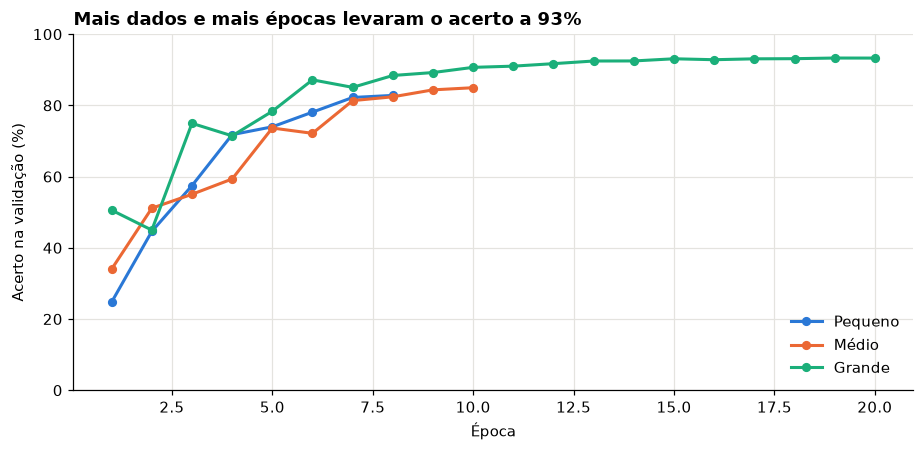

In [3]:
fig, eixo = plt.subplots(figsize=(8.5, 4.2))
for pasta, nome in {"cnn_3d_pequeno": "Pequeno", "cnn_3d_medio": "Médio", "cnn_3d": "Grande"}.items():
    h = pd.read_csv(R / pasta / "historico.csv")
    eixo.plot(h.epoca + 1, h.top1_val * 100, color=CORES[nome], linewidth=2, marker="o", markersize=5, label=nome)
eixo.set_xlabel("Época"); eixo.set_ylabel("Acerto na validação (%)"); eixo.set_ylim(0, 100)
eixo.set_title("Mais dados e mais épocas levaram o acerto a 93%")
eixo.legend(loc="lower right"); fig.tight_layout(); plt.show()

### Comparação na validação completa

Mesmos 14.787 vídeos, sendo 2.001 sem gesto. Os modelos grande e médio não foram treinados nas mesmas condições dos pequenos.

In [4]:
linhas, curvas = [], {}
for pasta, nome in MODELOS.items():
    a = json.loads((R / pasta / "avaliacao_falsas.json").read_text(encoding="utf-8"))
    curvas[nome] = pd.DataFrame(a["curva"])
    p = curvas[nome].set_index("limiar")
    linhas.append({"modelo": nome, "acerto": a["top1"], "falsa ativação (0,8)": p.loc[0.8, "falsa_ativacao"], "gestos (0,8)": p.loc[0.8, "gestos_acertados"],
                   "falsa ativação (0,9)": p.loc[0.9, "falsa_ativacao"], "gestos (0,9)": p.loc[0.9, "gestos_acertados"], "ruído (0,6)": a["sinteticos"]["ruido"]["0.6"]})
pd.DataFrame(linhas).style.format({c: "{:.1%}" for c in ["acerto", "gestos (0,8)", "gestos (0,9)"]} | {c: "{:.2%}" for c in ["falsa ativação (0,8)", "falsa ativação (0,9)", "ruído (0,6)"]}).hide(axis="index")

modelo,acerto,"falsa ativação (0,8)","gestos (0,8)","falsa ativação (0,9)","gestos (0,9)","ruído (0,6)"
Pequeno,82.3%,0.30%,33.1%,0.10%,18.4%,2.73%
Só sintéticos,80.1%,0.25%,28.1%,0.10%,14.8%,0.00%
Peso 1,78.2%,0.20%,22.6%,0.10%,11.4%,0.00%
Peso 2,75.7%,0.25%,18.1%,0.15%,9.0%,0.00%
Médio,84.9%,0.15%,53.4%,0.15%,39.2%,0.00%
Grande,93.3%,0.20%,77.9%,0.15%,67.0%,0.00%


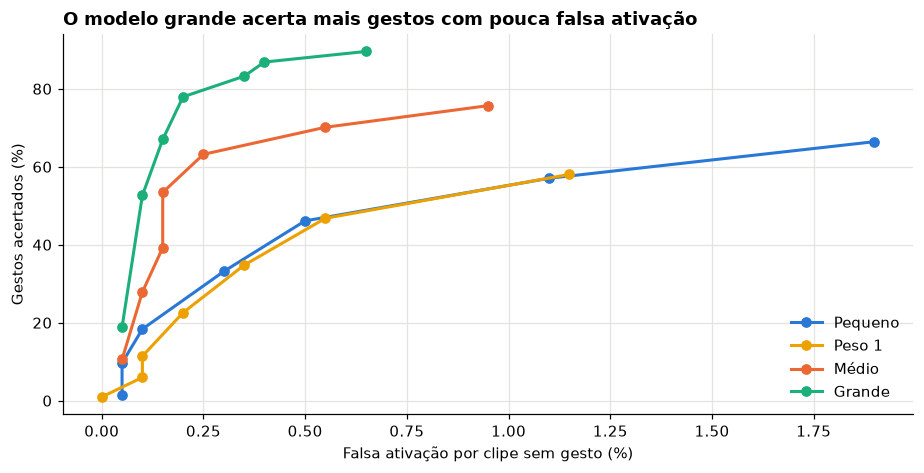

In [5]:
fig, eixo = plt.subplots(figsize=(8.5, 4.4))
for nome in ["Pequeno", "Peso 1", "Médio", "Grande"]:
    c = curvas[nome].sort_values("limiar", ascending=False)
    eixo.plot(c.falsa_ativacao * 100, c.gestos_acertados * 100, color=CORES[nome], linewidth=2, marker="o", markersize=6, label=nome)
eixo.set_xlabel("Falsa ativação por clipe sem gesto (%)"); eixo.set_ylabel("Gestos acertados (%)")
eixo.set_title("O modelo grande acerta mais gestos com pouca falsa ativação")
eixo.legend(loc="lower right"); fig.tight_layout(); plt.show()

### Falsos disparos por minuto

Fluxo simulado com cerca de 100 min de vídeos sem gesto, colados, e 1.500 vídeos com gesto. Com tão poucos eventos a incerteza é grande, e o valor não vale para o carro.

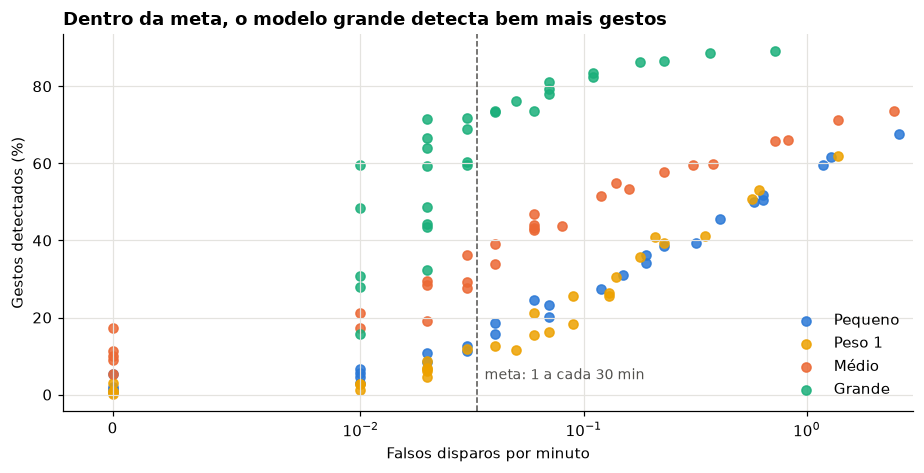

modelo,limiar,janelas_seguidas,falsos_por_min,falsos,gestos_detectados,disparos_classe_errada
Grande,0.70,3,0.030,3,71.8%,4.8%
Médio,0.60,6,0.030,3,36.2%,3.0%
Pequeno,0.80,4,0.030,3,12.6%,0.4%
Peso 1,0.90,1,0.030,3,11.9%,0.3%


In [6]:
todas = []
for pasta, nome in {"cnn_3d_pequeno": "Pequeno", "cnn_3d_pequeno_p1": "Peso 1", "cnn_3d_medio": "Médio", "cnn_3d": "Grande"}.items():
    todas.append(pd.read_csv(R / pasta / "calibracao_fluxo.csv").assign(modelo=nome))
fluxo = pd.concat(todas)
META = 1 / 30
fig, eixo = plt.subplots(figsize=(8.5, 4.4))
for nome in ["Pequeno", "Peso 1", "Médio", "Grande"]:
    f = fluxo[fluxo.modelo == nome]
    eixo.scatter(f.falsos_por_min, f.gestos_detectados * 100, color=CORES[nome], s=36, label=nome, alpha=0.85)
eixo.axvline(META, color="#52514e", linestyle="--", linewidth=1)
eixo.text(META * 1.08, 4, "meta: 1 a cada 30 min", color="#52514e", fontsize=9)
eixo.set_xscale("symlog", linthresh=0.01); eixo.set_xlim(-0.002, 3)
eixo.set_xlabel("Falsos disparos por minuto"); eixo.set_ylabel("Gestos detectados (%)")
eixo.set_title("Dentro da meta, o modelo grande detecta bem mais gestos")
eixo.legend(loc="lower right"); fig.tight_layout(); plt.show()
melhores = fluxo[fluxo.falsos_por_min <= META].sort_values("gestos_detectados", ascending=False).groupby("modelo").head(1)
melhores[["modelo", "limiar", "janelas_seguidas", "falsos_por_min", "falsos", "gestos_detectados", "disparos_classe_errada"]].style.format(
    {"limiar": "{:.2f}", "falsos_por_min": "{:.3f}", "gestos_detectados": "{:.1%}", "disparos_classe_errada": "{:.1%}"}).hide(axis="index")

### O que os resultados permitem concluir

- **A rede aprende do zero:** 92,6% no teste do Jester.
- **O que mais ajudou:** a combinação de mais dados, mais épocas e variações de treino. Como mudou tudo junto, não dá para separar o efeito de cada item.
- **Punição:** nos modelos pequenos, ela não superou o modelo sem punição no mesmo nível de falsa ativação. O peso 1 ficou na receita final, mas isso não prova que ele tenha causado a melhora.
- **Transformer e GRU:** não há conclusão. O transformer usou a mesma taxa de aprendizado, sem ajuste próprio, e a GRU foi interrompida.
- **Validação engana:** com cerca de 80% na validação, a demo ainda falhava com gestos rápidos.
- **Limite principal:** tudo isso vale para mão no ar, diante de webcam. No volante, ainda não há resultado.

## 6. Coleta de dados no carro

O prompt abaixo gera, em outra IA, uma página para gravar gestos no carro. **Grave só com o carro parado.** A câmera fica no painel, atrás do volante e acima dele, olhando para baixo em direção ao motorista. Rótulos de esquerda e direita se referem à mão do motorista, e o vídeo não pode ser espelhado.

Os rótulos marcam a janela em que o gesto foi pedido, não o instante exato do movimento. Se aparecer o rosto, trate como dado pessoal. O termo de consentimento deve ser revisado pelo professor.

```text
Crie um único arquivo HTML, com CSS e JavaScript embutidos e sem servidor, para coletar um dataset de gestos de mão no volante de um carro. Interface em português do Brasil. Nada é enviado pela internet.

Segurança: mostre em destaque "Grave apenas com o carro parado, em local seguro. Nunca use dirigindo." e exija marcar "O carro está parado".
Consentimento: antes de ligar a câmera, mostre um termo curto (o que é gravado, uso acadêmico no Insper, direito de desistir e pedir exclusão). Não peça nome nem e-mail.
Configuração: ID do participante (P001), mão dominante, condição de luz, posição da câmera (painel atrás do volante, painel central, outra), lado do volante e câmera.
Vídeo: 1280x720, 30 fps, sem áudio, em WebM com MP4 como alternativa. Pré-visualização e vídeo salvo sem espelhamento.
Gestos, para cada mão: swipe_direita, swipe_esquerda, flick_cima, flick_baixo, tap.
Blocos, cada um em um vídeo contínuo:
1. Gestos: 8 repetições de cada gesto em cada mão, em ordem aleatória com semente salva. Ciclo: Prepare 1,5 s, Agora 2,5 s, Descanse 2 a 4 s. Texto grande e voz (SpeechSynthesis).
2. Gestos rápidos: as mesmas classes, feitos sem olhar e o mais rápido possível, com observacao=rapido.
3. Sem gesto: 2 minutos com as mãos paradas.
4. Outros movimentos: 40 s de cada: ajustar a pegada, girar o volante, coçar o rosto, falar gesticulando, mexer no painel e no câmbio. Rótulo: outro.
5. Livre: 3 minutos conversando e mexendo as mãos, sem gesto de comando. Rótulo: fluxo_sem_gesto.
Botões: pausar, repetir o último (marca invalido=1), marcar erro, encerrar e salvar.
Tempos: em relação ao início do vídeo, com requestVideoFrameCallback e performance.now como alternativa. Nunca use setTimeout como medida.
Arquivo anotacoes.csv com: id_participante,id_sessao,bloco,arquivo_video,indice_pedido,rotulo,mao,inicio_ms,fim_ms,inicio_frame,fim_frame,invalido,observacao
Também classes.json, metadados.json e LEIA-ME.txt.
Salvar: com showDirectoryPicker, crie sessao_<ID>_<data>_<luz>/ com vídeos e arquivos. Sem essa API, gere um ZIP com JSZip embutido. Grave em disco durante a captura sempre que possível.
Trate permissão negada, câmera desconectada, falta de espaço e aba em segundo plano. Use Wake Lock. Inclua um Modo de teste de 1 minuto.
Entregue o HTML completo em um único bloco de código e diga como testar.
```

## 7. Próximos passos

1. **Terminar o download do DriverMHG:** faltam 56 de 125 gravações, e o download retoma de onde parou.
2. **Preparar as gravações:** `src/preparar_drivermhg.py`, que também retoma.
3. **Experimento central:** treino do zero × pré-treino no Jester, com menos e mais pessoas no treino. Essa é a figura principal do paper.
4. **Falsos disparos no volante:** em fluxo contínuo, com as pessoas 19 a 25.
5. **Demais experimentos:** RGB × RGB + infravermelho, latência, vocabulário de 3, 5 e 7 gestos, e CNN 3D × CNN + GRU.
6. **Melhorias pendentes:** escolher o melhor modelo também pela falsa ativação, ajustar a taxa do transformer se ele for mantido, e testar uma janela mais curta para a latência.
7. **Dados no carro:** gravar com a página da seção 6.
8. **Com o professor:** confirmar o pré-treino próprio e revisar o termo de consentimento.
9. **Notebook:** atualizar o driver da NVIDIA e deixar a tampa aberta durante os treinos.

## 8. Diário

Registro feito ao longo do projeto, na ordem em que aconteceu. **[V]** é verificado, **[E]** é estimativa e **[?]** é ainda não confirmado.

## 04/11/2026: acesso, licença e contagens

### DriverMHG

- **[V]** 4 partes RAR, totalizando 19,95 GB. Download sem cadastro; baixar já implica aceitar a licença.
- **[V]** 25 pessoas, 5 gravações por pessoa, 42 segmentos anotados por gravação. Total de 5.148 segmentos: 3.702 no treino (pessoas 1-18) e 1.446 no teste (pessoas 19-25).
- **[V]** 14 classes, cerca de 360 segmentos cada: 5 gestos, `None` e `Other`, para cada mão.
- **[V]** Duração média de 28 frames (0,94 s). O toque é o mais curto, com cerca de 20 frames (0,67 s).
- **[V]** Gravado em **simulador de direção**, não em carro real, com 5 condições de luz: sala, escuro, luz à esquerda, luz à direita e luz intensa dos dois lados.
- **[V]** Cada frame é um JPG separado, e o RAR não é sólido. Por isso dá para pular a profundidade no download.
- **[V]** Velocidade medida no servidor: 0,15 MB/s. O arquivo completo levaria cerca de 37 h **[E]**.
- **[?]** Os arquivos de classes numeram os gestos de formas diferentes. O código oficial usa `FlickDown`, `FlickUp`, `SwipeLeft`, `SwipeRight`, `Tap`. Conferir olhando os frames.

### Licença do DriverMHG

- **[V]** Sem redistribuição, nem dentro da mesma universidade: cada integrante baixa a própria cópia.
- **[V]** No máximo 10 frames e 2 clipes em documentos publicados, salvo aprovação da TUM.
- **[V]** Sem modificar os dados nem uso comercial sem aprovação. **[?]** Não está claro se redimensionar para treino conta como modificação.
- **[V]** Citar Köpüklü et al. (2020), arXiv:2003.00951.

### Referência a superar

- **[V]** Com pré-treino no Jester, por mão: 91,5% em RGB, 91,6% em infravermelho e 92,9% em RGB + infravermelho (melhores valores da Tabela I do artigo).
- **[V]** Em fluxo contínuo, a acurácia de Levenshtein cai para 74%.
- **[?]** Não encontrei falsos disparos por minuto nos trechos lidos do artigo.

### Jester

- **[V]** 22,8 GB em TGZ dividido em partes, 148.092 vídeos, JPG com 100 px de altura, 12 fps (instruções da Qualcomm).
- **[?]** Cadastro e licença não confirmados por aqui. O PDF de licença da Qualcomm que li é de outro dataset (Exercise Video).

### Pontos de atenção

- Não há fluxo sem gesto: só os intervalos entre os segmentos anotados. Estimativa de cerca de 73 min no teste **[E]**, a partir de uma gravação; com zero disparos, o limite superior ainda seria de cerca de 0,04 por minuto.
- A demo por webcam vem de uma câmera diferente da usada no treino, o que é um risco de desempenho.
- Confirmar com o professor se o pré-treino próprio no Jester respeita a regra de treino do zero.

### Decisões

- Baixar o DriverMHG sem profundidade: cerca de 13 GB e 25 h **[E]**. A profundidade foi a pior modalidade no artigo, e nenhum experimento depende dela.
- O Jester só entra depois de vermos os dados do DriverMHG.

## 04/11/2026: primeira gravação e exploração

### Download

- **[V]** Teste na pessoa 1, gravação 1: 5.201 frames em RGB e 5.201 em infravermelho, em 320×240. Nenhum frame corrompido na amostra de 1 em cada 200.
- **[V]** A gravação ocupa 77 MB sem profundidade e levou 8 min, a cerca de 0,17 MB/s.
- **[E]** Total sem profundidade: cerca de 10 GB e 17 h, menos do que os 13 GB e 25 h estimados antes.

### Exploração (`notebooks/01_exploracao.ipynb`)

- **[V]** Listas oficiais: 5.148 segmentos, 25 pessoas, sem pessoa em comum entre treino e teste.
- **[V]** Cada pessoa tem de 186 a 214 segmentos.
- **[V]** Duração média de 28,1 frames (0,94 s): 27,3 no treino e 30,3 no teste. O toque tem 20,3 frames (0,68 s).
- **[V]** Há segmentos muito curtos, de 4 a 10 frames, a conferir.
- **[V]** Na gravação testada, 70,8% dos frames (123 s de 173 s) não têm anotação, e os gestos ocorrem a cada 5,6 s (mediana).
- **[E]** Teste inteiro: cerca de 72 min sem anotação, assumindo o mesmo valor nas 35 gravações. Com zero disparos, o limite superior ainda seria de cerca de 0,04 por minuto.

### Observações

- A câmera filma de frente para o volante, com as mãos pequenas na imagem, e o volante gira durante a direção. O gesto pode ser um movimento menor que o da própria direção.
- A cena é bem diferente da do Jester (mão diante de webcam). Isso pode reduzir o ganho do pré-treino e afeta a demo.
- **[?]** Só olhando as tiras de frames não deu para confirmar o nome de cada gesto. Por enquanto vale a numeração do `create_json.py` oficial.
- As tiras ficam em `data/interno/`, fora do git, por causa do limite da licença.

## 04/11/2026: Jester e redes

### Acesso e licença do Jester

- **[V]** Download público, sem login, por 3 partes (10 + 10 + 2,93 GB) e um arquivo de rótulos. Velocidade medida: cerca de 11 MB/s.
- **[V]** Divisão oficial: 118.562 treino, 14.787 validação, 14.743 teste. O pacote também traz as respostas do teste.
- **[V]** Licença: *Data License Agreement - Research Use*, de 28/07/2022. Baixar já implica aceitar. O usuário autorizou o download.
- **[V]** Condições: só pesquisa sem fins lucrativos e uso interno; os dados são confidenciais; não mostrar nem distribuir os dados a terceiros; não combinar os dados com dados de terceiros.
- **[?]** Consequências a confirmar: frames do Jester não devem ir para o paper nem para a apresentação. Treinar separadamente no Jester e depois ajustar no DriverMHG não mistura os dados, mas essa leitura é nossa, não é parecer jurídico. Cada integrante do grupo deve baixar a própria cópia.

### Decisão de armazenamento

Os cerca de 5 milhões de JPG não são extraídos em arquivos separados: ficam em `jester_frames.bin`, com um índice, e o `.tgz` não fica em disco.

### Redes (treinadas do zero)

- CNN 2D + GRU: 1.574.907 parâmetros. CNN 3D: 3.522.747 parâmetros.
- Entrada: 16 frames, 96×96. Sem inversão horizontal, porque ela troca a classe dos gestos de direção.
- **[V]** Teste com dados aleatórios, lote de 48, precisão mista: 193 vídeos/s (CNN+GRU) e 160 vídeos/s (CNN 3D), com pico de 5,8 GB na GPU. Ainda falta medir a velocidade com o carregador real.

## 04/11/2026: ajuste fino com outros dados

O usuário pesquisou e informou que treinar no Jester e ajustar no DriverMHG é permitido, da forma como o projeto faz. Decisão: seguir com esse plano. Os dados continuam separados: o Jester só entra no pré-treino, e o DriverMHG, no ajuste. A fonte dessa confirmação não foi registrada aqui; para o paper, convém anotar qual foi.

## 04/11/2026: início do treino no Jester

- **[V]** Índice concluído: 5.279.581 frames, 148.092 vídeos, 27,13 GB. Frames conferidos por amostragem contra o download (1 em cada 1.000), e o tamanho total bate.
- **[V]** Teste com dados reais, 4.000 vídeos, 1 época: cerca de 133 vídeos/s; validação com 12,7% de acerto (só para checar o fluxo; o acaso seria cerca de 3,7%).
- **[E]** Cerca de 15 min por época e 5,5 h por rede em 20 épocas.
- **Decisões:** treinar primeiro a CNN 3D, depois a CNN + GRU; 16 frames, 96×96, lote de 48, AdamW com OneCycle (lr máximo de 1e-3), suavização de rótulos de 0,1, seed 42. O teste só é avaliado uma vez, com o melhor modelo da validação.

## 04/11/2026: treino pequeno antes do grande

O usuário pediu um treino menor para validar a ideia. O treino completo foi interrompido depois de 1 época inteira, e seus arquivos foram apagados.

- **[V]** Medido antes de parar: CNN 3D, 118.562 vídeos, 1 época, 49,65% de acerto na validação (top-5 de 84,30%). Velocidade real: cerca de 185 vídeos/s fora das pausas.
- **Novo plano:** CNN 3D com 20 mil vídeos em 8 épocas (cerca de 15 min). Depois, comparar no DriverMHG o treino do zero com o pré-treino, usando só as pessoas já baixadas e separando uma pessoa para teste.
- **Limite:** o DriverMHG baixa em ordem textual (1, 10, 11...), então só a pessoa 1 e a 10 estavam prontas neste momento. A comparação pequena será fraca e serve só para testar o fluxo.

## 04/11/2026: treino pequeno e falsas ativações

- **[V]** CNN 3D do zero, 20 mil vídeos, 8 épocas, 1,8 min por época: 82,8% de acerto na validação (5 mil vídeos), top-5 de 98,0%.
- **[V]** Falsa ativação por vídeo sem gesto, na validação, por limiar: 1,85% em 0,5; 1,14% em 0,6; 0,43% em 0,7; 0,28% em 0,8; 0% em 0,9. Gestos acertados caem junto: 66,9%, 57,3%, 46,7%, 33,6%, 18,2%.
- **[V]** Em ruído puro, 2,7% dos clipes ativam em 0,6 e 0% em 0,9.
- **[E]** A taxa é por clipe, não por minuto. Em fluxo contínuo há até 300 janelas por minuto, muito correlacionadas entre si, então 1,14% pode significar vários disparos por minuto. Precisa ser medido em fluxo.
- O disparo em ruído com 76% de confiança foi visto com o modelo da época 6, em um único teste, e não se repetiu como regra no modelo final.
- **Demo:** `demo/abrir_camera.bat`. Janela de cerca de 3 s, com atraso bem acima de 300 ms.
- **Próximo:** comparar com a versão punida (`--peso-falso 5 --frac-sinteticos 0.15`).

## 04/11/2026: a punição forte piorou o modelo curto

Comparação nas mesmas condições (CNN 3D, 20 mil vídeos, 8 épocas, 5 mil vídeos de validação):

| Falsa ativação | Sem punição: gestos acertados | Com peso 5 e 15% de sintéticos: gestos acertados |
|---|---|---|
| cerca de 0,43% | 46,7% (limiar 0,7) | 29,5% (limiar 0,6) |
| cerca de 0,28% | 33,6% (limiar 0,8) | 19,4% (limiar 0,7) |

- **[V]** Acerto geral: 82,8% contra 70,7%. Em ruído, ativação em 0,6: 2,7% contra 0%.
- **Leitura:** nesta rodada, a punição faz o modelo responder menos e pior, sem ganho no mesmo nível de falsa ativação. Pelo critério definido antes do treino, ela não vale.
- **Limites:** 8 épocas podem ser pouco para esse modelo, que aprende mais devagar. A validação tem poucos negativos, então cada clipe vale cerca de 0,14% de falsa ativação, e a medida é por clipe, não por minuto.
- **Decisão:** não levar o peso 5 adiante. Próximos testes: só negativos sintéticos (10%), e um gatilho temporal em fluxo, que pode ser o caminho mais eficaz. Também rodam CNN + transformer e CNN + GRU, para comparar arquiteturas.

## 04/11/2026: primeiro retorno da webcam

**Relato do usuário (modelo do peso 1):** reconhece o joinha com pouca confiança, só depois de cerca de 10 s na mesma posição e muito perto da câmera. Movimentos rápidos, como arrastar para os lados, não são capturados.

**Hipóteses, ainda não confirmadas:**
1. A demo olhava 3 s a 5,3 frames por segundo, então um gesto rápido caía em poucos frames.
2. O treino sempre viu o vídeo inteiro, com o gesto ocupando a maior parte da janela.
3. Punição e suavização de rótulos reduzem a confiança.
4. O modelo pequeno usou só 17% dos dados e 8 épocas.
5. A mão aparece menor na webcam do que no Jester.

**Mudanças:**
- **Demo:** 12 frames por segundo no buffer, janelas de 1, 1,5 e 3 s, miniatura com o que o modelo vê e fps real da câmera. Ficar com a janela mais confiante pode aumentar os falsos disparos.
- **Treino `cnn_3d_curto`:** trechos e velocidades variados (`--aug-tempo`), suavização de 0,05, peso 1 e 10% de sintéticos, 10 épocas.

**Lição:** a validação (cerca de 80%) não previu esse problema, porque usa clipes recortados. A partir de agora, o teste com webcam entra como critério.

## 04/11/2026: treino médio de cerca de 45 min

O usuário pediu um treino um pouco maior, com o que aprendemos, para ver se o modelo evolui.

- **`cnn_3d_medio`:** CNN 3D, 40 mil vídeos (o dobro), 10 épocas.
- **Receita:** peso de punição 1, 10% de negativos sintéticos, trechos e velocidades variados, mão menor e fora do centro, suavização de 0,05.
- **Arquitetura mantida:** mudar a rede ao mesmo tempo impediria saber o que causou a melhora.
- **Limite:** ao mudar várias coisas juntas, este treino mostra se a receita evolui, mas não qual item ajudou. As augmentações podem reduzir o acerto na validação, que usa clipes recortados e centralizados. Por isso, o teste na webcam faz parte da avaliação.

## 04/11/2026: tela azul durante o treino médio

- **[V]** O sistema reiniciou por volta de 15h55 com o bugcheck `0x113` (`VIDEO_DXGKRNL_FATAL_ERROR`), que aponta para o subsistema de vídeo. Os parâmetros citam o fabricante `10de` (NVIDIA) e o dispositivo `0x2d59`. O despejo está em `C:\Windows\Minidump\110426-32343-01.dmp`.
- **[V]** Não houve botão de energia, suspensão nem evento térmico nos registros consultados, e o notebook estava na tomada.
- **[?]** A causa exata não foi determinada. O treino mantém a GPU em 100%, e antes foram vistos 85-88 °C e 112 W, mas isso não prova que a carga tenha sido a causa. Sem análise do despejo, driver e carga continuam como hipóteses.
- **Perda:** 1 época em andamento. Havia 6 épocas salvas, a 72,2% de acerto na validação, e 13 gravações do DriverMHG. O treino e o download foram retomados.
- **Registro:** temperatura e potência da GPU em `resultados/gpu_log.csv`, a cada 30 s.

## 04/11/2026: `cnn_3d_medio` na webcam

- **[V]** Treino concluído: 85,0% na validação (10 mil vídeos), top-5 de 98,1%; no limiar 0,6, 0,60% de falsa ativação e 70,3% dos gestos acertados.
- **Relato do usuário na webcam:** boa precisão e reconhecimento praticamente instantâneo em polegar para cima, polegar para baixo, sinal de pare e deslizar a mão para a esquerda e para a direita. Antes, o joinha demorava cerca de 10 s e os movimentos rápidos não eram capturados.
- **Limites:** é o teste de uma pessoa, em um ambiente, sem medida numérica. Treino e demo mudaram juntos (mais dados, épocas, augmentações, janelas curtas), então não dá para atribuir a melhora a um único item. Falsos disparos na webcam ainda não foram informados. Não vale como resultado para o carro.

## 04/11/2026: player por gestos

- **`demo/player.py` + `demo/player.html`:** o modelo roda localmente (servidor só em 127.0.0.1) e a página sintetiza 5 músicas originais, sem arquivos nem direitos autorais.
- **Comandos:** Swiping Left volta, Swiping Right avança, Stop Sign alterna play e pause.
- **Gatilho:** confiança de pelo menos 0,6 em 2 janelas seguidas, 1,2 s de pausa, e é preciso soltar o gesto para repetir. Isso evita alternar play e pause sem parar enquanto a mão fica parada.
- **[V]** Testes: lógica do gatilho, envio de eventos e vídeo. **[?]** A página em si não foi clicada por mim: o Chrome não conectou e o `node` não está instalado, então nem a sintaxe do JavaScript foi verificada por ferramenta.

## 04/11/2026: teste do player na webcam

- **Relato do usuário:** funciona. Nenhum comando disparou sozinho. Arrastar para a esquerda sempre funcionou; para a direita, às vezes confunde o lado, mas funciona. A duração do teste não foi registrada, então isso não é uma taxa por minuto.
- **[V]** Na validação completa (modelo médio): Swiping Left acerta 88,9% (n=494) e 1,0% vira Swiping Right. Swiping Right acerta 88,5% (n=486) e 2,5% vira Swiping Left. Stop Sign acerta 84,9% (n=536) e 9,0% vira Pushing Hand Away.
- **Leitura:** a diferença entre os lados é pequena nos dados, e as contagens são baixas (5 contra 12 vídeos), então o problema na webcam pode estar mais ligado ao jeito de fazer o gesto ou à mão usada do que ao modelo em geral. Hipótese ainda não testada.

## 04/11/2026: calibração concluída e início do treino grande

**Validação completa (14.787 vídeos, 2.001 sem gesto), gestos acertados e falsa ativação por clipe:**

| Modelo | Acerto | Limiar 0,7 | Limiar 0,8 | Limiar 0,9 |
|---|---|---|---|---|
| Pequeno, sem punição | 82,3% | 46,1% / 0,50% | 33,2% / 0,30% | 18,4% / 0,10% |
| Só sintéticos | 80,1% | 40,5% / 0,60% | 28,1% / 0,25% | 14,8% / 0,10% |
| Peso 1 | 78,2% | 34,8% / 0,35% | 22,6% / 0,20% | 11,4% / 0,10% |
| Peso 2 | 75,8% | 29,2% / 0,25% | 18,1% / 0,25% | 9,0% / 0,15% |
| **Médio (40 mil, 10 épocas, augmentações)** | **84,9%** | **63,2% / 0,25%** | **53,4% / 0,15%** | **39,2% / 0,15%** |

**Fluxo simulado (100,2 min sem gesto, 1.500 vídeos com gesto, uma janela de 3 s):**

| Modelo | Limiar, janelas | Falsos/min | Gestos detectados | Classe errada |
|---|---|---|---|---|
| Médio | 0,6, 2 (como o player) | 0,379 | 59,9% | 10,3% |
| Médio | 0,7, 3 | 0,060 | 44,0% | 4,6% |
| Médio | 0,8, 4 | 0,020 | 29,4% | 1,9% |
| Médio | 0,9, 2 | 0,020 | 28,5% | 1,3% |
| Pequeno | 0,9, 2 | 0,020 | 10,7% | 0,2% |
| Peso 1 | 0,8, 4 | 0,020 | 8,8% | 0,1% |

**Leitura:**
- A meta de 0,033 falsos/min é atingida pelo médio, com 29% de detecção. É cerca de 3 vezes a dos pequenos, mas ainda é baixa para uso real.
- O critério de falsa ativação até 0,25% e erro até 1% é atendido pelo médio no limiar 0,9.
- Na mesma falsa ativação, peso 1 e peso 2 não superaram o modelo sem punição; a melhora veio da combinação de mais dados e augmentações. Mudanças feitas juntas não permitem separar o efeito de cada item.
- O fluxo tem 100 min, então 2 eventos têm intervalo de confiança largo. Os vídeos sem gesto de "Doing other things" são movimentos difíceis e todos os 25 gestos contam como disparo; no player, só 3. Por isso, o player real deve disparar menos. O medidor usa uma janela, e a demo, três.

**Decisão:** manter a receita do médio no treino grande (118.562 vídeos, 20 épocas, seed 42): peso 1, 10% de sintéticos, augmentações, suavização de 0,05. O teste é usado uma vez, ao final.

## 04/11/2026: treino grande no Jester

**Configuração:** CNN 3D do zero (3,5 milhões de parâmetros), 118.562 vídeos, 20 épocas, peso de punição 1, 10% de negativos sintéticos, trechos e velocidades variados, mão menor e fora do centro, suavização de 0,05. Melhor época: 19 de 20, escolhida pelo acerto na validação.

**[V] Resultado:**

| Conjunto | Vídeos | Top-1 | Top-5 |
|---|---|---|---|
| Validação | 14.787 | 93,3% | 99,5% |
| **Teste, usado uma vez** | 14.743 | **92,6%** | **99,4%** |

| Limiar | Falsa ativação (val / teste) | Gestos acertados (val / teste) | Gestos errados (val / teste) |
|---|---|---|---|
| 0,6 | 0,40% / 0,32% | 86,9% / 86,4% | 3,0% / 3,2% |
| 0,7 | 0,35% / 0,26% | 83,2% / 83,3% | 2,0% / 2,3% |
| 0,8 | 0,20% / 0,26% | 77,9% / 77,8% | 1,4% / 1,6% |
| 0,9 | 0,15% / 0,05% | 67,0% / 67,0% | 0,7% / 0,9% |

**[V] Fluxo simulado em validação (100,2 min sem gesto, 1.500 vídeos com gesto):**

| Limiar, janelas | Falsos/min | Falsos | Gestos detectados | Classe errada |
|---|---|---|---|---|
| 0,6, 2 | 0,110 | 11 | 83,4% | 9,7% |
| **0,7, 3 (escolhido)** | **0,030** | **3** | **71,8%** | **4,8%** |
| 0,8, 3 | 0,020 | 2 | 64,0% | 3,3% |
| 0,9, 2 | 0,030 | 3 | 59,5% | 2,7% |

**Comparação:** o modelo médio, na meta, detectava 29,4%; o grande chega a 71,8%, cerca de 2,4 vezes mais.

**Decisão:** ponto de operação 0,7 e 3 janelas, escolhido na validação, por atender à meta de 0,033 falsos/min com a maior detecção.

**Limites:**
- 3 eventos em 100 min têm IC de 95% de cerca de 0,006 a 0,088 por minuto (Poisson exato), então o fluxo não garante a meta.
- O fluxo usa clipes colados e todos os 25 gestos; o valor não vale para outra câmera nem para o carro.
- O critério do melhor modelo ainda é só o acerto geral.
- Os 94,6% citados pelo artigo do DriverMHG usam outra rede e outro protocolo, e não são comparação direta.

## 04/11/2026: fim do dia

- **Relato do usuário:** o modelo grande está performando muito bem no teste ao vivo. Teste qualitativo, de uma pessoa, em webcam.
- **Salvo:** `resultados/jester/cnn_3d/melhor.pt`.
- **Próximo passo:** terminar o download do DriverMHG, preparar as gravações e rodar no volante a comparação entre treino do zero e pré-treino no Jester. É o experimento central da tese, ainda sem resultado.